<a href="https://colab.research.google.com/github/asndjkasdnjkasdjnkasdj/-Lab01_EDA_Azocar_Benjamin/blob/main/EEG.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


# Clasificación de condiciones experimentales mediante EEG

**IEI097 · Minería de Datos · Unidad III · Actividad 3.5**  
**Grupo 01:** Benjamín Azócar y Omar López.

- **Informe CRISP-DM:** [Informe](https://github.com/asndjkasdnjkasdjnkasdj/-Lab01_EDA_Azocar_Benjamin/blob/main/IEI097_Informe_G01.pdf).
- **Repositorio del proyecto:** [Repositorio](https://github.com/asndjkasdnjkasdjnkasdj/-Lab01_EDA_Azocar_Benjamin).
- **Datos:** [EEG Brainwave Dataset: Mental State, versión 2](https://www.kaggle.com/datasets/birdy654/eeg-brainwave-dataset-mental-state).

## Objetivo y decisión que apoyamos

Evaluar si las características EEG permiten distinguir las condiciones de **relajación, neutralidad y concentración**, identificar qué condiciones se confunden y apoyar la decisión de realizar un segundo piloto o revisar primero el protocolo de captura. Es una **clasificación supervisada multiclase**: cada fila tiene una etiqueta conocida.

El laboratorio de interacción humano-computador es el contexto propuesto en nuestro informe. No contamos con un encargo de un laboratorio real. Las predicciones se refieren a condiciones del experimento; no constituyen una medición clínica de los estados mentales.

## Compromisos del informe

| Elemento | Decisión previa al entrenamiento |
|---|---|
| Semilla | **213410806** |
| Modelo base | `DummyClassifier(strategy="most_frequent")` |
| Familias | Regresión logística con L2 y Random Forest |
| Variables principales | 512 características de la ventana actual |
| H1 | El mejor RF supera al mejor LR en **al menos 0,03** de F1 macro medio en validación |
| H2 | Agregar 476 características `lag1_` al RF seleccionado mejora **al menos 0,02**, conservando configuración y pliegues |
| Separación | Primer pliegue de `StratifiedGroupKFold(5)` para prueba; 3 pliegues por grupos dentro del entrenamiento |
| Selección | Mayor F1 macro medio; si la diferencia entre las mejores familias es menor que 0,01, se prefiere LR |
| Éxito técnico | F1 macro de prueba **≥ 0,70**; informar la diferencia frente al modelo base |
| Recomendación de otro piloto | Además, recall **≥ 0,60 en cada clase** |

**Adaptación a la Actividad 3.5.** El informe contemplaba evaluar en prueba al ganador y al modelo base. La pauta nueva pide comparar los tres modelos. Evaluaremos también la mejor configuración de la otra familia, después de dejar fijado el ganador por validación. Esta ampliación se registra en la sección 8 y no permite cambiar la elección mirando la prueba.

## Preparación del entorno

Se utilizó Google Colab con CPU y el entorno 2026.07, que incluye Python 3.12. Se fijó scikit-learn 1.5.2 para reproducir las particiones del informe. La instalación utiliza NumPy 2.0.2, pandas 2.2.2 y SciPy 1.14.1, versiones que quedaron registradas en la ejecución.

Se retiraron `hdbscan` y `umap-learn`, paquetes de clustering preinstalados que este proyecto no utiliza y cuyos requisitos entraban en conflicto con scikit-learn 1.5.2. Este ajuste corresponde a la preparación del entorno y se documenta en el registro de cambios.

Las credenciales `KAGGLE_API_TOKEN` y `NGROK_AUTHTOKEN` se gestionan mediante Colab Secrets. MLflow se ejecuta en el mismo entorno y su interfaz se consulta mediante un túnel de ngrok.

En una sesión nueva, se instala antes de importar las bibliotecas. Tras la primera instalación se reinicia la sesión y se continúa con las importaciones. En las ejecuciones posteriores del mismo entorno preparado se pueden ejecutar todas las celdas en orden. [Documentación de versiones de Colab](https://research.google.com/colaboratory/runtime-version-faq.html).

In [ ]:
import sys

assert sys.version_info[:2] == (3, 12), \
    "Selecciona el entorno 2026.07 (Python 3.12) de Colab."

# Estos paquetes de clustering no se utilizan en nuestro proyecto
# y requieren otra versión de scikit-learn.
%pip uninstall -y hdbscan umap-learn

%pip install -q "numpy==2.0.2" "pandas==2.2.2" "scipy==1.14.1" "scikit-learn==1.5.2" "matplotlib==3.10.8" "mlflow==3.18.0" "kagglehub==1.0.3" "pyngrok==9.1.4" joblib threadpoolctl

Found existing installation: hdbscan 0.8.44
Uninstalling hdbscan-0.8.44:
  Successfully uninstalled hdbscan-0.8.44
Found existing installation: umap-learn 0.5.12
Uninstalling umap-learn-0.5.12:
  Successfully uninstalled umap-learn-0.5.12
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 60.8/60.8 kB 518.5 kB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 52.8/52.8 kB 1.7 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 50.5/50.5 kB 1.6 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 40.4/40.4 kB 1.4 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 51.4/51.4 kB 1.7 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.3/44.3 kB 1.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 40.8/40.8 MB 11.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.9/12.9 MB 9.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.7/8.7 MB 37.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12

In [ ]:
import numpy as np
import pandas as pd
import scipy
import sklearn

print("NumPy:", np.__version__)
print("pandas:", pd.__version__)
print("SciPy:", scipy.__version__)
print("scikit-learn:", sklearn.__version__)

NumPy: 2.0.2
pandas: 2.2.2
SciPy: 1.14.1
scikit-learn: 1.5.2


In [ ]:
import os
for variable in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS"):
    os.environ[variable] = "1"

import sys, io, json, random, hashlib, time, uuid, warnings, subprocess, shutil, sqlite3
from pathlib import Path
from collections import defaultdict
from datetime import datetime
from zoneinfo import ZoneInfo
from importlib.metadata import version
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import requests, joblib, sklearn, mlflow
from IPython.display import display, Markdown, Image
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedGroupKFold, cross_val_score
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay)
from sklearn.exceptions import ConvergenceWarning
from threadpoolctl import threadpool_limits

SEED = 213410806
GRUPO = "G01"
random.seed(SEED)
np.random.seed(SEED)
assert sklearn.__version__ == "1.5.2", "Reinicia y usa las versiones indicadas."
IN_COLAB = "COLAB_RELEASE_TAG" in os.environ or "google.colab" in sys.modules
ROOT = Path("/content/Proyecto_EEG_G01") if IN_COLAB else Path.cwd() / "Proyecto_EEG_G01"
LOTE = datetime.now(ZoneInfo("America/Santiago")).strftime("%Y%m%d_%H%M%S") + "_" + uuid.uuid4().hex[:6]
RUN_DIR = ROOT / LOTE
RUN_DIR.mkdir(parents=True)
EVIDENCIAS = RUN_DIR / "evidencias_mlflow"
EVIDENCIAS.mkdir()
CLASES = [0, 1, 2]
NOMBRES = ["Relajación", "Neutral", "Concentración"]
MAPA = dict(zip(CLASES, NOMBRES))
EXPECTED_SHA = "59ad0f29fa7265916e31d058a72a1d071a0a3be9a501fabd15b3f2b5c7d88b94"

# Completar estos enlaces antes de entregar. El enlace al PDF debe abrir el informe.
URL_REPO = "https://github.com/asndjkasdnjkasdjnkasdj/-Lab01_EDA_Azocar_Benjamin"
URL_INFORME = "https://github.com/asndjkasdnjkasdjnkasdj/-Lab01_EDA_Azocar_Benjamin/blob/main/IEI097_Informe_G01.pdf"
# Después de tomar y subir las capturas, pegar sus URL raw de GitHub.
URL_CAPTURAS = {
    "01_lista_runs.png": "",
    "02_compare.png": "",
    "03_artefactos.png": "",
}

def guardar_json(objeto, nombre):
    destino = RUN_DIR / nombre
    destino.write_text(json.dumps(objeto, ensure_ascii=False, indent=2), encoding="utf-8")
    return destino

paquetes = ["numpy", "pandas", "scipy", "scikit-learn", "matplotlib", "mlflow", "kagglehub", "pyngrok", "joblib", "threadpoolctl"]
versiones = {p: version(p) for p in paquetes}
guardar_json({"python": sys.version, "paquetes": versiones, "seed": SEED, "lote": LOTE}, "entorno.json")
(RUN_DIR / "requirements.txt").write_text("\n".join(f"{p}=={v}" for p, v in versiones.items()), encoding="utf-8")
display(pd.Series(versiones, name="Versión"))
print("Carpeta de esta ejecución:", RUN_DIR)

,Versión
numpy,2.0.2
pandas,2.2.2
scipy,1.14.1
scikit-learn,1.5.2
matplotlib,3.10.8
mlflow,3.18.0
kagglehub,1.0.3
pyngrok,9.1.4
joblib,1.5.3
threadpoolctl,3.6.0


Carpeta de esta ejecución: /content/Proyecto_EEG_G01/20261119_011349_8f42c5


## 1. Carga reproducible de los datos

Descargamos **la versión 2** directamente de Kaggle con `kagglehub`, sin carga manual de archivos. Contrastamos su SHA-256, tamaño y esquema con el Anexo B del informe. Si no coinciden, detenemos el análisis y revisamos el cambio de fuente.

La ficha describe cuatro participantes, una banda Muse y los canales TP9, AF7, AF8 y TP10. El CSV contiene características calculadas de ventanas EEG, no las señales crudas. Los códigos del generador del autor son **0 = relajación, 1 = neutral y 2 = concentración**. Véanse el [dataset](https://www.kaggle.com/datasets/birdy654/eeg-brainwave-dataset-mental-state) y el [generador de características](https://github.com/jordan-bird/eeg-feature-generation).

La ficha muestra la licencia como **“Other (specified in description)”** y solicita citar a Bird et al. (2018). Conservamos esa información y la referencia del informe; la solicitud de citar no especifica por sí sola todos los permisos de una licencia.

In [ ]:
import kagglehub
carpeta_datos = Path(kagglehub.dataset_download(
    "birdy654/eeg-brainwave-dataset-mental-state/versions/2"))
archivos = list(carpeta_datos.rglob("mental-state.csv"))
assert len(archivos) == 1, f"Revisar la descarga: {archivos}"
raw_bytes = archivos[0].read_bytes()
sha = hashlib.sha256(raw_bytes).hexdigest()
assert sha == EXPECTED_SHA, "El archivo no coincide con el auditado en el informe."
assert len(raw_bytes) == 61588897
original = pd.read_csv(io.BytesIO(raw_bytes))
assert original.shape == (2479, 989)
assert original.columns.is_unique and original.columns[-1] == "Label"
assert set(original.Label.unique()) == set(CLASES)
display(original.head())
print("Filas:", original.shape[0], "| Columnas:", original.shape[1])
original.info()
display(original.dtypes.value_counts().to_frame("Columnas"))
guardar_json({"fuente": "Kaggle, versión 2", "url": "https://www.kaggle.com/datasets/birdy654/eeg-brainwave-dataset-mental-state",
    "sha256": sha, "bytes": len(raw_bytes), "clases": MAPA}, "dataset.json")

100%|██████████| 24.1M/24.1M [00:00<00:00, 136MB/s] 

Extracting files...


,lag1_mean_0,lag1_mean_1,lag1_mean_2,lag1_mean_3,lag1_mean_d_h2h1_0,lag1_mean_d_h2h1_1,lag1_mean_d_h2h1_2,lag1_mean_d_h2h1_3,lag1_mean_q1_0,lag1_mean_q1_1,...,freq_669_3,freq_679_3,freq_689_3,freq_699_3,freq_709_3,freq_720_3,freq_730_3,freq_740_3,freq_750_3,Label
0,25.781648,33.836367,-92.769629,19.187957,-1.542262,0.197462,-119.561133,2.032654,21.596272,33.965587,...,0.000230,0.000351,0.000547,0.000381,0.000350,0.000453,0.000442,0.000325,0.000209,2.0
1,29.357891,26.792566,417.203910,19.472121,-38.797263,-16.897194,-29.368531,-9.055370,44.647424,40.893307,...,0.001671,0.000740,0.001122,0.000521,0.000624,0.000439,0.001249,0.000727,0.000801,2.0
2,28.451926,31.076434,72.231301,14.245938,-13.225057,-0.614138,-28.331698,-8.858742,31.450289,30.692883,...,0.000748,0.000569,0.000327,0.000197,0.000833,0.000909,0.000699,0.001165,0.000616,2.0
3,21.282184,19.985184,16.220094,39.787312,1.847866,0.670216,-1.820355,20.220724,21.404679,20.777411,...,0.000990,0.005644,0.006891,0.010546,0.009583,0.011158,0.008853,0.004551,0.002287,1.0
4,20.431516,28.982168,27.540246,19.960398,2.491458,-6.020503,-1.071166,2.655259,16.295039,32.658163,...,0.001659,0.014379,0.014492,0.002949,0.004575,0.008305,0.007202,0.006957,0.009836,2.0


Filas: 2479 | Columnas: 989
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2479 entries, 0 to 2478
Columns: 989 entries, lag1_mean_0 to Label
dtypes: float64(989)
memory usage: 18.7 MB


,Columnas
float64,989


PosixPath('/content/Proyecto_EEG_G01/20261119_011349_8f42c5/dataset.json')

## 2. Análisis exploratorio de los datos

Primero reproducimos el diagnóstico estructural del informe: nulos, finitud, duplicados y alertas de valores extremos. Después retiramos los duplicados, reconstruimos los grupos y reservamos la prueba. **Los estadísticos y gráficos para estudiar relaciones y preparar los modelos usan exclusivamente entrenamiento.**

Esta separación evita usar el comportamiento de la prueba para elegir variables o ajustar transformaciones. Los controles iniciales de todo el archivo ya formaban parte de la auditoría de datos del informe.

In [ ]:
pred_original = original.drop(columns="Label")
q1 = pred_original.quantile(0.25)
q3 = pred_original.quantile(0.75)
ric = q3 - q1
alertas = pred_original.lt(q1 - 1.5 * ric) | pred_original.gt(q3 + 1.5 * ric)
diagnostico = {
    "filas": len(original), "columnas": len(original.columns),
    "predictores": pred_original.shape[1], "nulos": int(original.isna().sum().sum()),
    "infinitos": int(np.isinf(original.to_numpy()).sum()),
    "duplicados_exactos": int(original.duplicated().sum()),
    "duplicados_pct": float(100 * original.duplicated().mean()),
    "predictores_constantes": int((pred_original.nunique(dropna=False) <= 1).sum()),
    "alertas_RIC_celdas": int(alertas.sum().sum()),
    "alertas_RIC_pct": float(100 * alertas.to_numpy().mean()),
    "filas_con_alertas": int(alertas.any(axis=1).sum()),
    "columnas_con_alertas": int(alertas.any(axis=0).sum()),
}
assert [diagnostico[k] for k in ("nulos", "infinitos", "duplicados_exactos", "predictores_constantes")] == [0, 0, 115, 0]
assert diagnostico["alertas_RIC_celdas"] == 174221
display(pd.Series(diagnostico).to_frame("Valor"))
display(original.isna().sum().sort_values(ascending=False).head(10).to_frame("Nulos por columna"))
display(original.groupby("Label").size().rename(index=MAPA).to_frame("Filas originales"))
guardar_json(diagnostico, "diagnostico.json")
pd.DataFrame({"nulos": original.isna().sum(), "tipo": original.dtypes.astype(str)}).to_csv(RUN_DIR / "calidad_columnas.csv")
original.loc[original.duplicated()].to_csv(RUN_DIR / "duplicados_retirados.csv", index=True)

,Valor
filas,2479.000000
columnas,989.000000
predictores,988.000000
nulos,0.000000
infinitos,0.000000
duplicados_exactos,115.000000
duplicados_pct,4.638967
predictores_constantes,0.000000
alertas_RIC_celdas,174221.000000
alertas_RIC_pct,7.113233


,Nulos por columna
Label,0
lag1_mean_0,0
lag1_mean_1,0
lag1_mean_2,0
lag1_mean_3,0
lag1_mean_d_h2h1_0,0
lag1_mean_d_h2h1_1,0
lag1_mean_d_h2h1_2,0
lag1_mean_d_h2h1_3,0
lag1_mean_q1_0,0


,Filas originales
Label,
Relajación,819
Neutral,830
Concentración,830


**Interpretación del diagnóstico.** El archivo auditado tiene 2.479 filas y 989 columnas: 988 predictores y `Label`, todos leídos como `float64`. La etiqueta es nominal, aunque esté almacenada como número. No hay nulos, infinitos ni predictores constantes. Retiramos 115 copias exactas, todas de concentración, conservando la primera aparición.

Las 174.221 alertas de RIC representan alrededor del 7,11 % de las celdas de predictores. Todas las filas tienen alguna alerta. Eliminarlas solo por esa regla descartaría el conjunto completo; conservamos los valores finitos porque la regla no demuestra un error de captura.

### Grupos de ventanas y prevención de fuga

Relacionamos las 476 características `lag1_` con sus equivalentes de la ventana actual. Si dos filas coinciden en el vector completo alineado, creamos un vínculo y reunimos las filas conectadas. Los hashes buscan candidatos; la igualdad de los valores verifica cada vínculo. **No se usa la etiqueta para formar los grupos.**

Un grupo reúne ventanas relacionadas que podemos detectar. No identifica necesariamente a una persona o una sesión. Conservar estos grupos completos reduce la dependencia entre conjuntos, pero no garantiza una evaluación con participantes diferentes.

In [ ]:
datos = original.drop_duplicates(keep="first").copy()
filas_csv = datos.index.to_numpy()
datos = datos.reset_index(drop=True)
y = datos.Label.astype(int)
X = datos.drop(columns="Label")
assert X.shape == (2364, 988)
assert y.value_counts().sort_index().tolist() == [819, 830, 715]
assert not X.duplicated().any(), "Revisar posibles etiquetas en conflicto."
lag_cols = [c for c in X if c.startswith("lag1_") and c[5:] in X]
equivalentes = [c[5:] for c in lag_cols]
actual_cols = [c for c in X if not c.startswith("lag1_")]
assert len(lag_cols) == 476 and len(actual_cols) == 512
actuales = X[equivalentes].to_numpy()
anteriores = X[lag_cols].to_numpy()
hash_actual = pd.util.hash_pandas_object(X[equivalentes], index=False)
hash_lag = pd.util.hash_pandas_object(X[lag_cols].set_axis(equivalentes, axis=1), index=False)
indices_por_hash = defaultdict(list)
padre = list(range(len(X)))

def raiz(i):
    while i != padre[i]:
        padre[i] = padre[padre[i]]
        i = padre[i]
    return i

for i, h in enumerate(hash_actual):
    indices_por_hash[h].append(i)
enlaces = []
for j, h in enumerate(hash_lag):
    for i in indices_por_hash[h]:
        if i != j and np.array_equal(actuales[i], anteriores[j]):
            padre[raiz(j)] = raiz(i)
            enlaces.append((i, j))
grupos = np.array([raiz(i) for i in range(len(X))])
assert len(enlaces) == 2340 and len(np.unique(grupos)) == 24
grupo_filas = pd.DataFrame({"fila_limpia": np.arange(len(X)), "fila_csv": filas_csv,
    "grupo": grupos, "clase": y})
resumen_grupos = grupo_filas.groupby("grupo").agg(filas=("clase", "size"),
    clases=("clase", "nunique"), clase=("clase", "first"))
assert resumen_grupos.clases.eq(1).all()
display(resumen_grupos)
grupo_filas.to_csv(RUN_DIR / "grupos.csv", index=False)
pd.DataFrame(enlaces, columns=["actual", "anterior"]).to_csv(RUN_DIR / "enlaces.csv", index=False)

,filas,clases,clase
grupo,,,
109,116,1,0
137,86,1,2
159,5,1,2
331,116,1,1
458,116,1,1
563,102,1,2
575,116,1,0
884,116,1,1
1142,116,1,0


In [ ]:
externa = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
idx_train, idx_test = next(externa.split(X, y, grupos))
assert (len(idx_train), len(idx_test)) == (1798, 566)
assert set(grupos[idx_train]).isdisjoint(grupos[idx_test])
assert y.iloc[idx_train].value_counts().sort_index().tolist() == [703, 598, 497]
assert y.iloc[idx_test].value_counts().sort_index().tolist() == [116, 232, 218]
X_train, X_test = X.iloc[idx_train].copy(), X.iloc[idx_test].copy()
y_train, y_test = y.iloc[idx_train].copy(), y.iloc[idx_test].copy()
grupos_train, grupos_test = grupos[idx_train], grupos[idx_test]
interna = StratifiedGroupKFold(n_splits=3, shuffle=True, random_state=SEED)
pliegues = list(interna.split(X_train, y_train, grupos_train))
esperados = [[123, 233, 122], [348, 132, 173], [232, 233, 202]]
registro = []
for n, (ent, val) in enumerate(pliegues):
    assert set(grupos_train[ent]).isdisjoint(grupos_train[val])
    assert set(y_train.iloc[ent]) == set(CLASES)
    assert y_train.iloc[val].value_counts().sort_index().tolist() == esperados[n]
    registro.append({"pliegue": n + 1, "train": idx_train[ent].tolist(), "validacion": idx_train[val].tolist()})
guardar_json({"seed": SEED, "sha256": sha, "sklearn": sklearn.__version__,
    "train": idx_train.tolist(), "test": idx_test.tolist(), "pliegues_internos": registro}, "particion.json")
display(pd.DataFrame({"Entrenamiento": y_train.value_counts(), "Prueba": y_test.value_counts()}).sort_index().rename(index=MAPA))
display(pd.DataFrame(esperados, columns=NOMBRES, index=["Validación 1", "Validación 2", "Validación 3"]))
print("Grupos en entrenamiento:", len(np.unique(grupos_train)), "| En prueba:", len(np.unique(grupos_test)))

,Entrenamiento,Prueba
Label,,
Relajación,703,116
Neutral,598,232
Concentración,497,218


,Relajación,Neutral,Concentración
Validación 1,123,233,122
Validación 2,348,132,173
Validación 3,232,233,202


Grupos en entrenamiento: 19 | En prueba: 5


### Estadísticos descriptivos

Los conteos reproducen las Tablas B1 y B2 del informe: 1.798 filas de entrenamiento, 566 de prueba y ninguna coincidencia de grupos entre conjuntos. Las proporciones no son exactamente 80/20 porque conservamos grupos completos. Todos los pliegues contienen las tres clases.

Calculamos los estadísticos de los 988 predictores de entrenamiento y guardamos la tabla completa. Para facilitar la lectura mostramos diez variables que representan varios tipos de características. Esta selección es solo para visualizar; los modelos principales siguen usando las 512 variables actuales.

In [ ]:
vars_eda = ["mean_0", "mean_1", "std_0", "std_1", "skew_0", "kurt_0",
    "covM_0_2", "logcovM_0_2", "freq_010_0", "topFreq_1_0"]
assert set(vars_eda).issubset(X.columns)
descriptivos = X_train.describe().T
descriptivos.to_csv(RUN_DIR / "descriptivos_entrenamiento.csv")
display(descriptivos.loc[vars_eda])
display(X_train[vars_eda].groupby(y_train).median().rename(index=MAPA))
pd.DataFrame({"variable": X.columns, "tipo": X.dtypes.astype(str).to_numpy(),
    "ventana": ["anterior" if c.startswith("lag1_") else "actual" for c in X]}).to_csv(RUN_DIR / "columnas.csv", index=False)

,count,mean,std,min,25%,50%,75%,max
mean_0,1798.0,23.776918,9.352630,-20.351414,19.133100,23.470869,27.274103,94.853197
mean_1,1798.0,26.032872,22.619710,-369.150109,20.312307,25.856045,30.782155,408.180215
std_0,1798.0,17.939875,11.109099,6.712276,11.226283,14.489568,18.765503,85.943475
std_1,1798.0,12.917398,32.638985,2.588877,5.605179,6.892417,8.735533,607.554890
skew_0,1798.0,-0.203168,0.638518,-3.996413,-0.383492,-0.076637,0.158996,1.952422
kurt_0,1798.0,0.187233,1.622328,-1.296282,-0.649317,-0.308074,0.241478,20.913617
covM_0_2,1798.0,233.899986,1220.767270,-17263.762513,-4.114593,19.117480,55.653600,11804.301939
logcovM_0_2,1798.0,0.180953,0.161960,0.000485,0.066401,0.136020,0.246342,0.983067
freq_010_0,1798.0,0.094247,0.085648,0.001287,0.030974,0.071038,0.125065,0.563311
topFreq_1_0,1798.0,3.992612,6.286499,1.013514,1.013514,2.027027,4.054054,65.878378


,mean_0,mean_1,std_0,std_1,skew_0,kurt_0,covM_0_2,logcovM_0_2,freq_010_0,topFreq_1_0
Label,,,,,,,,,,
Relajación,22.640234,23.488988,14.600212,6.659896,-0.003565,-0.668178,13.680093,0.104301,0.084607,3.040541
Neutral,23.420326,24.945277,12.735003,7.038153,-0.083725,-0.108322,13.181266,0.196681,0.112525,2.027027
Concentración,27.019551,31.120246,16.696566,7.388693,-0.219830,0.071203,711.609837,0.152540,0.024965,2.027027


**Interpretación de los estadísticos.** La media de un canal, una covarianza y una magnitud de FFT representan cantidades distintas y pueden tener rangos muy diferentes. Comparar sus valores absolutos no permite determinar cuál es más importante. Para LR estandarizamos cada característica usando solamente el entrenamiento de cada pliegue; RF conserva su escala original. Las medianas por clase son una descripción y no demuestran que una característica cause la condición.

### Distribución de la variable objetivo

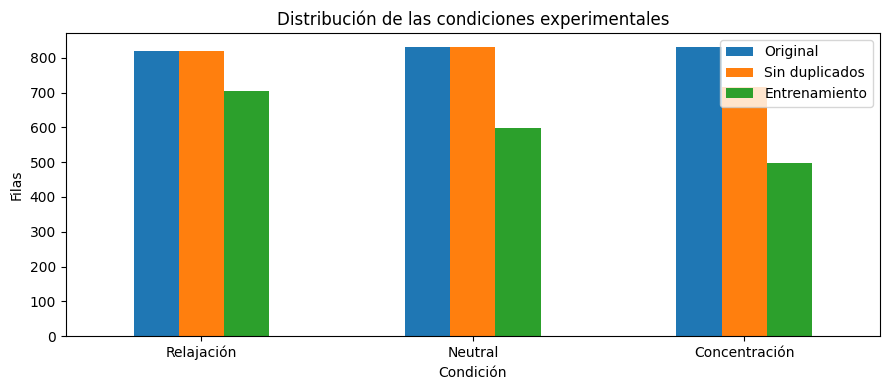

,Original,Sin duplicados,Entrenamiento
Label,,,
Relajación,819,819,703
Neutral,830,830,598
Concentración,830,715,497


In [ ]:
balance = pd.DataFrame({
    "Original": original.Label.value_counts().reindex(CLASES),
    "Sin duplicados": y.value_counts().reindex(CLASES),
    "Entrenamiento": y_train.value_counts().reindex(CLASES),
}).rename(index=MAPA)
fig, ax = plt.subplots(figsize=(9, 4))
balance.plot.bar(ax=ax, rot=0)
ax.set(title="Distribución de las condiciones experimentales", xlabel="Condición", ylabel="Filas")
fig.tight_layout()
fig.savefig(RUN_DIR / "eda_clases.png", dpi=150)
plt.show()
display(balance)
balance.to_csv(RUN_DIR / "balance_clases.csv")

**Interpretación del gráfico de clases.** Las frecuencias originales son próximas: 819, 830 y 830. Tras retirar las 115 copias de concentración quedan 819, 830 y 715. En entrenamiento hay 703 ejemplos de relajación, 598 neutrales y 497 de concentración. Por eso el modelo base aprende a predecir relajación. Usamos F1 macro para que ninguna clase domine la selección por tener más ejemplos. Mantenemos la preparación prevista, sin agregar sobremuestreo.

### Distribuciones de características

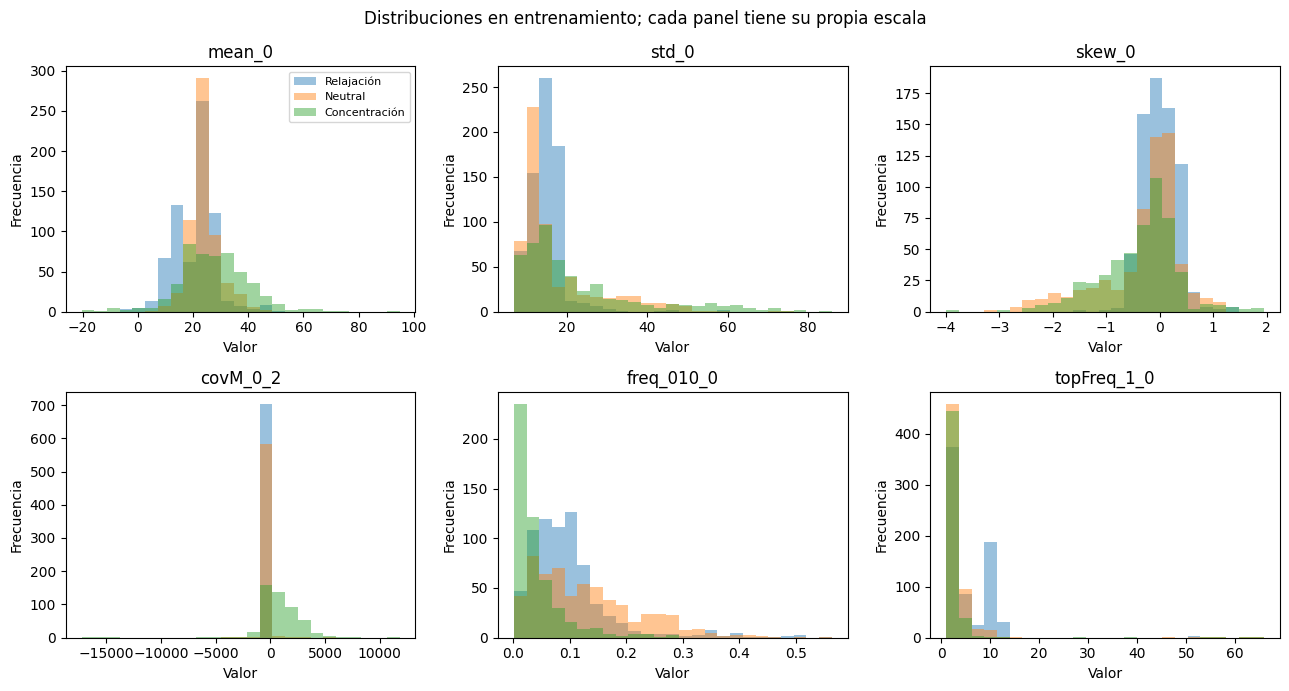

In [ ]:
vars_hist = ["mean_0", "std_0", "skew_0", "covM_0_2", "freq_010_0", "topFreq_1_0"]
fig, axes = plt.subplots(2, 3, figsize=(13, 7))
for ax, variable in zip(axes.flat, vars_hist):
    limites = np.histogram_bin_edges(X_train[variable], bins=25)
    for clase in CLASES:
        ax.hist(X_train.loc[y_train == clase, variable], bins=limites, alpha=0.45, label=MAPA[clase])
    ax.set(title=variable, xlabel="Valor", ylabel="Frecuencia")
axes.flat[0].legend(fontsize=8)
fig.suptitle("Distribuciones en entrenamiento; cada panel tiene su propia escala")
fig.tight_layout()
fig.savefig(RUN_DIR / "eda_distribuciones.png", dpi=150)
plt.show()

**Interpretación de los histogramas.** En `mean_0`, las tres condiciones se superponen y concentración presenta una distribución más amplia. `std_0` y `freq_010_0` muestran colas hacia valores altos. `topFreq_1_0` concentra muchas observaciones en frecuencias bajas. `covM_0_2` tiene una escala mucho mayor que los otros ejemplos. Dentro de cada panel usamos los mismos intervalos para las tres clases; entre paneles las escalas son distintas. El gráfico usa frecuencias, por lo que también influye el número de ejemplos por clase. Un valor aislado no ofrece una separación garantizada entre condiciones. No añadimos transformaciones logarítmicas ni selección de variables a partir de estos gráficos.

### Diagramas de caja y valores extremos

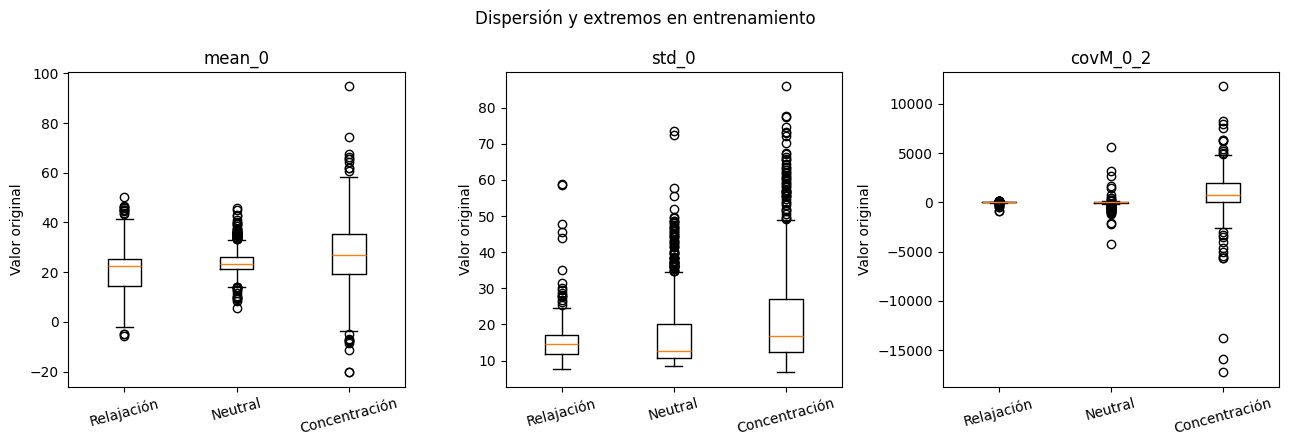

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4.5))
for ax, variable in zip(axes, ["mean_0", "std_0", "covM_0_2"]):
    ax.boxplot([X_train.loc[y_train == c, variable].to_numpy() for c in CLASES],
        tick_labels=NOMBRES, showfliers=True)
    ax.set(title=variable, ylabel="Valor original")
    ax.tick_params(axis="x", rotation=15)
fig.suptitle("Dispersión y extremos en entrenamiento")
fig.tight_layout()
fig.savefig(RUN_DIR / "eda_boxplots.png", dpi=150)
plt.show()

**Interpretación de los diagramas de caja.** Las cajas resumen la mediana y el rango intercuartílico; los puntos fuera de los bigotes son alertas de extremos, no errores comprobados. Concentración muestra una mayor dispersión en `mean_0` y `covM_0_2`; también aparecen extremos de `std_0` en las tres clases. Las diferencias ayudan a entender el diagnóstico de RIC y aconsejan no confundir un extremo con un dato inválido. Conservamos esos valores, como acordamos en el informe. `StandardScaler` cambia la escala para LR, pero no elimina los extremos ni es un tratamiento robusto frente a ellos.

### Correlaciones entre predictores

Calculamos la matriz completa de Pearson de las 512 variables actuales de entrenamiento. Mostramos diez variables para que sus nombres se lean y guardamos la matriz completa como CSV. `Label` se excluye porque sus códigos son categorías.

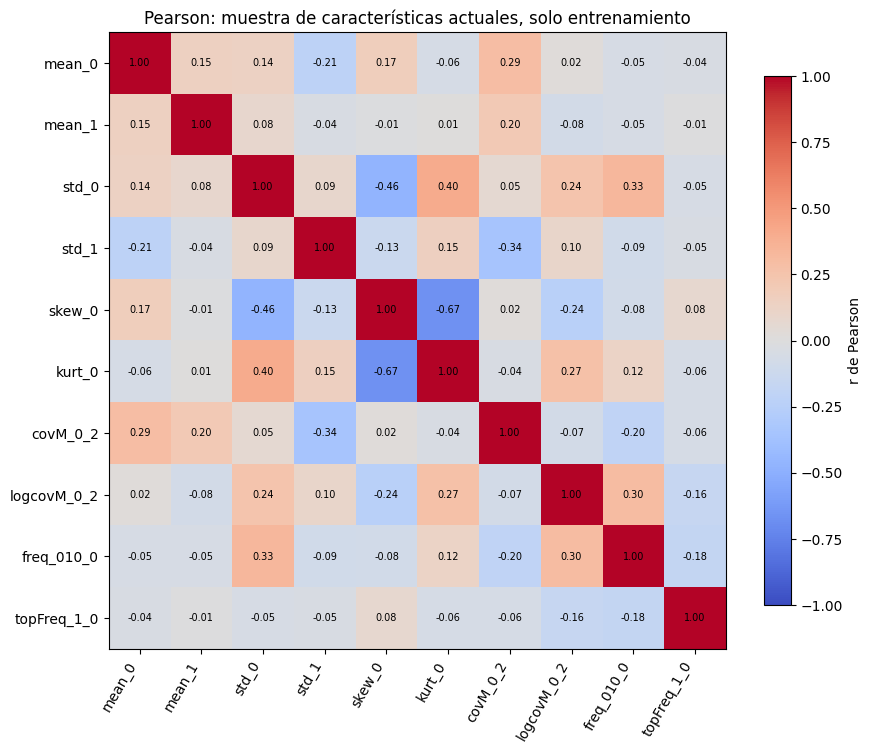

,variable_1,variable_2,r,abs_r
69395,covM_0_1,covM_1_3,0.978191,0.978191
71478,covM_2_2,eigenval_0,0.975595,0.975595
23511,std_0,covM_0_0,0.960069,0.960069
24441,std_2,covM_2_2,0.959184,0.959184
24903,std_3,covM_3_3,0.957157,0.957157
32940,max_d_h2h1_1,max_d_q1q4_1,-0.955217,0.955217
69042,covM_0_0,covM_0_3,0.954969,0.954969
25248,std_d_h2h1_0,std_d_h2h1_3,0.939405,0.939405
24388,std_2,min_2,-0.939132,0.939132
24444,std_2,eigenval_0,0.934404,0.934404


In [ ]:
corr_completa = X_train[actual_cols].corr()
corr_completa.to_csv(RUN_DIR / "correlaciones_actuales_entrenamiento.csv")
corr = corr_completa.loc[vars_eda, vars_eda]
fig, ax = plt.subplots(figsize=(9, 8))
im = ax.imshow(corr, vmin=-1, vmax=1, cmap="coolwarm")
ax.set_xticks(range(len(vars_eda)), vars_eda, rotation=60, ha="right")
ax.set_yticks(range(len(vars_eda)), vars_eda)
for i in range(len(vars_eda)):
    for j in range(len(vars_eda)):
        ax.text(j, i, f"{corr.iloc[i,j]:.2f}", ha="center", va="center", fontsize=7)
ax.set_title("Pearson: muestra de características actuales, solo entrenamiento")
fig.colorbar(im, ax=ax, label="r de Pearson", shrink=0.75)
fig.tight_layout()
fig.savefig(RUN_DIR / "eda_correlaciones.png", dpi=150)
plt.show()
mascara = np.triu(np.ones(corr_completa.shape, dtype=bool), k=1)
pares = corr_completa.where(mascara).stack().rename("r").reset_index()
pares.columns = ["variable_1", "variable_2", "r"]
pares["abs_r"] = pares.r.abs()
display(pares.sort_values("abs_r", ascending=False).head(10))
pares.to_csv(RUN_DIR / "pares_correlacion.csv", index=False)

**Interpretación de la matriz.** En la muestra visible, `skew_0` y `kurt_0` tienen una relación negativa de alrededor de −0,67; `std_0` y `skew_0`, de −0,46. Los valores próximos a 1 o −1 en la tabla completa de pares señalan posible información redundante entre las 512 variables actuales. Esto respalda probar la regularización L2 ya prevista y comparar con árboles. Una correlación baja no descarta relaciones no lineales. Conservamos las variables del informe y no atribuimos causalidad a estas asociaciones.

## 3. Preparación dentro de un Pipeline

| Evidencia | Decisión implementada |
|---|---|
| 115 filas repetidas | Retirar las copias exactas antes de agrupar y dividir; conservar índices para auditoría |
| No hay nulos ni infinitos | No imputar el archivo auditado; las comprobaciones detienen la ejecución si cambia |
| Predictores numéricos | Separar `Label`; no se necesita codificación de categorías en X |
| Escalas diferentes | `StandardScaler` solo en LR y dentro del Pipeline |
| Extremos sin evidencia de error | Conservar valores finitos |
| Ventanas relacionadas | Particiones por grupos inferidos; ningún grupo se comparte |
| Comparación principal | El selector del Pipeline deja pasar exclusivamente las 512 variables actuales |
| H2 | Otro Pipeline deja pasar las 988 variables, con la misma configuración de RF |

La eliminación de duplicados y la reconstrucción de grupos son controles anteriores a la partición. El selector usa nombres fijados por el esquema, sin aprender de la etiqueta. **La media y desviación del escalador se ajustan de nuevo en cada entrenamiento interno**, porque `cross_val_score` clona y ajusta todo el Pipeline. No ajustamos transformaciones fuera de él.

## 4. Modelado: referencia y dos familias

LR representa fronteras lineales regularizadas. RF combina árboles y puede aprender relaciones no lineales e interacciones. La búsqueda es exactamente la del informe: C = 0,1; 1; 10 para LR y cuatro combinaciones de profundidad y tamaño mínimo de hoja para RF. Los ocho candidatos son configuraciones de **tres tipos de modelo**, no ocho familias diferentes.

In [ ]:
def construir_pipeline(modelo, columnas, escalar=False):
    selector = ColumnTransformer([("variables", "passthrough", list(columnas))],
        remainder="drop", verbose_feature_names_out=False)
    return Pipeline([
        ("seleccion", selector),
        ("escala", StandardScaler() if escalar else "passthrough"),
        ("modelo", modelo),
    ])

candidatos = {"Dummy": construir_pipeline(
    DummyClassifier(strategy="most_frequent", random_state=SEED), actual_cols)}
familias = {"Dummy": "base"}
for C in (0.1, 1.0, 10.0):
    nombre = f"LR_C{C:g}"
    candidatos[nombre] = construir_pipeline(LogisticRegression(
        penalty="l2", C=C, solver="lbfgs", max_iter=2000, random_state=SEED), actual_cols, escalar=True)
    familias[nombre] = "regresion_logistica"
for profundidad in (8, 16):
    for minimo_hoja in (2, 5):
        nombre = f"RF_d{profundidad}_h{minimo_hoja}"
        candidatos[nombre] = construir_pipeline(RandomForestClassifier(
            n_estimators=200, max_depth=profundidad, min_samples_leaf=minimo_hoja,
            random_state=SEED, n_jobs=1), actual_cols)
        familias[nombre] = "random_forest"
assert len(candidatos) == 8
assert "Label" not in X_train and not {"grupo", "fila_csv", "fila_limpia"}.intersection(X_train.columns)
display(candidatos["LR_C1"])

Pipeline(steps=[('seleccion',
                 ColumnTransformer(transformers=[('variables', 'passthrough',
                                                  ['mean_0', 'mean_1', 'mean_2',
                                                   'mean_3', 'mean_d_h2h1_0',
                                                   'mean_d_h2h1_1',
                                                   'mean_d_h2h1_2',
                                                   'mean_d_h2h1_3', 'mean_q1_0',
                                                   'mean_q1_1', 'mean_q1_2',
                                                   'mean_q1_3', 'mean_q2_0',
                                                   'mean_q2_1', 'mean_q2_2',
                                                   'mean_q2_3', 'mean_q3_0',
                                                   'mean_q3_1', 'mean_q3_2',
                                                   'mean_q3_3', 'mean_q4_0',
                                                   'mean_q4_1', 'mean_q4_2',
                                                   'mean_q4_3', 'mean_d_q1q2_0',
                                                   'mean_d_q1q2_1',
                                                   'mean_d_q1q2_2',
                                                   'mean_d_q1q2_3',
                                                   'mean_d_q1q3_0',
                                                   'mean_d_q1q3_1', ...])],
                                   verbose_feature_names_out=False)),
                ('escala', StandardScaler()),
                ('modelo',
                 LogisticRegression(max_iter=2000, random_state=213410806))])

### Registro de experimentos con MLflow

Usamos el experimento **`IEI097-G01`**, como pide la pauta. Cada configuración tiene un run de validación. Después registramos tres runs finales: base, mejor LR y mejor RF. Todos incluyen las etiquetas `grupo` y `tipo_modelo`, la semilla, parámetros, métricas y gráficos. La etiqueta `lote` permite reconocer una ejecución completa.

Iniciamos MLflow en el propio entorno. La URL de ngrok sirve para abrir su interfaz en el navegador. En la interfaz elegimos **Model training → Experiments → IEI097-G01**. El registro desde Python usa la dirección local del servidor. Mantenemos la sesión conectada hasta tomar las capturas.

In [ ]:
PUERTO = 5000 if IN_COLAB else int(os.environ.get("EEG_PORT", "5057"))
TRACKING_URI = f"http://127.0.0.1:{PUERTO}"

def servidor_saludable():
    try:
        return requests.get(TRACKING_URI + "/health", timeout=2).ok
    except requests.RequestException:
        return False

if "servidor" not in globals() or servidor.poll() is not None:
    if servidor_saludable():
        raise RuntimeError(f"El puerto {PUERTO} está ocupado. Revisar antes de crear otro servidor.")
    ambiente = dict(os.environ,
        MLFLOW_SERVER_ALLOWED_HOSTS="*" if IN_COLAB else "localhost:*,127.0.0.1:*",
        MLFLOW_SERVER_CORS_ALLOWED_ORIGINS="*" if IN_COLAB else "http://localhost:*,http://127.0.0.1:*")
    with open(ROOT / "mlflow_server.log", "a", encoding="utf-8") as log:
        servidor = subprocess.Popen([sys.executable, "-m", "mlflow", "server",
            "--backend-store-uri", "sqlite:///" + (ROOT / "mlflow.db").as_posix(),
            "--serve-artifacts", "--artifacts-destination", str(ROOT / "mlartifacts"),
            "--host", "127.0.0.1", "--port", str(PUERTO), "--workers", "1"],
            cwd=ROOT, env=ambiente, stdout=log, stderr=subprocess.STDOUT)
    limite = time.monotonic() + 120
    while not servidor_saludable():
        if servidor.poll() is not None or time.monotonic() > limite:
            servidor.terminate()
            raise RuntimeError((ROOT / "mlflow_server.log").read_text(encoding="utf-8")[-5000:])
        time.sleep(1)
if IN_COLAB:
    from google.colab import userdata
    from pyngrok import ngrok
    ngrok.set_auth_token(userdata.get("NGROK_AUTHTOKEN"))
    ngrok.kill()
    tunel = ngrok.connect(PUERTO)
    print("Abre MLflow en el navegador:", tunel.public_url)
else:
    print("Interfaz local de MLflow:", TRACKING_URI)
mlflow.set_tracking_uri(TRACKING_URI)
experimento = mlflow.set_experiment("IEI097-G01")
EXPERIMENT_ID = experimento.experiment_id
print("Lote de esta ejecución:", LOTE)
print("Filtro para ver los tres runs finales:", f"tags.lote = '{LOTE}' AND tags.fase = 'prueba_final'")

Abre MLflow en el navegador: https://drank-turban-bottle.ngrok-free.dev


2026/11/19 04:20:32 INFO mlflow.tracking.fluent: Experiment with name 'IEI097-G01' does not exist. Creating a new experiment.


Lote de esta ejecución: 20261119_011349_8f42c5
Filtro para ver los tres runs finales: tags.lote = '20261119_011349_8f42c5' AND tags.fase = 'prueba_final'


In [ ]:
resultados_cv = {}

def registrar_contexto(nombre, tipo, fase, pipeline):
    columnas = pipeline.named_steps["seleccion"].transformers[0][2]
    mlflow.set_tags({"grupo": GRUPO, "tipo_modelo": tipo, "fase": fase,
        "lote": LOTE, "candidato": nombre, "sha256": sha})
    simples = {k: v for k, v in pipeline.get_params(deep=True).items()
        if v is None or isinstance(v, (str, int, float, bool))}
    mlflow.log_params({**simples, "semilla": SEED, "n_variables": len(columnas),
        "n_train": len(X_train), "n_test": len(X_test)})
    mlflow.log_dict(json.loads(json.dumps(pipeline.get_params(deep=True), default=str)), "parametros_completos.json")
    mlflow.log_dict({"columnas": columnas}, "columnas.json")
    for archivo in ("entorno.json", "dataset.json", "particion.json", "diagnostico.json"):
        mlflow.log_artifact(str(RUN_DIR / archivo), artifact_path="protocolo")

def validar(nombre, pipeline, tipo, fase="validacion"):
    if nombre in resultados_cv:
        display(pd.DataFrame([resultados_cv[nombre]]))
        return resultados_cv[nombre]
    with mlflow.start_run(run_name=f"CV_{nombre}") as run:
        registrar_contexto(nombre, tipo, fase, pipeline)
        inicio = time.perf_counter()
        with warnings.catch_warnings(record=True) as avisos:
            warnings.simplefilter("always")
            with threadpool_limits(limits=1):
                scores = cross_val_score(pipeline, X_train, y_train,
                    cv=pliegues, scoring="f1_macro", n_jobs=1, error_score="raise")
        convergencia = sum(issubclass(a.category, ConvergenceWarning) for a in avisos)
        resumen = {"candidato": nombre, "tipo_modelo": tipo,
            "cv_f1_macro_mean": float(scores.mean()), "cv_f1_macro_std": float(scores.std(ddof=1)),
            **{f"cv_f1_pliegue_{i}": float(s) for i, s in enumerate(scores, 1)},
            "avisos_convergencia": int(convergencia)}
        mlflow.log_metrics({k: v for k, v in resumen.items() if isinstance(v, (int, float))})
        mlflow.log_metric("segundos_cv", time.perf_counter() - inicio)
        for i, s in enumerate(scores, 1):
            mlflow.log_metric("cv_f1_macro", float(s), step=i)
        mlflow.log_dict({"avisos": [str(a.message) for a in avisos]}, "avisos.json")
        fig, ax = plt.subplots(figsize=(6, 4))
        ax.bar([1, 2, 3], scores)
        ax.axhline(scores.mean(), color="black", linestyle="--", label="Media")
        ax.set(xticks=[1, 2, 3], xlabel="Pliegue de validación", ylabel="F1 macro", title=f"{nombre}: validación por grupos", ylim=(0, 1))
        ax.legend()
        fig.tight_layout()
        destino = RUN_DIR / f"cv_{nombre}.png"
        fig.savefig(destino, dpi=150)
        plt.close(fig)
        mlflow.log_artifact(str(destino))
        mlflow.log_dict(resumen, "resumen_cv.json")
        resumen["run_id_cv"] = run.info.run_id
    resultados_cv[nombre] = resumen
    pd.DataFrame(resultados_cv.values()).to_csv(RUN_DIR / "todos_resultados_cv.csv", index=False)
    display(pd.DataFrame([resumen]))
    if convergencia:
        print("ATENCIÓN: revisar los avisos de convergencia antes de interpretar la comparación.")
    return resumen

🏃 View run CV_Dummy at: http://127.0.0.1:5000/#/experiments/1/runs/7fb0bd1d73b34a12bb17c9b69cb00075
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1


,candidato,tipo_modelo,cv_f1_macro_mean,cv_f1_macro_std,cv_f1_pliegue_1,cv_f1_pliegue_2,cv_f1_pliegue_3,avisos_convergencia,run_id_cv
0,Dummy,base,0.140195,0.030147,0.136439,0.112102,0.172043,0,7fb0bd1d73b34a12bb17c9b69cb00075


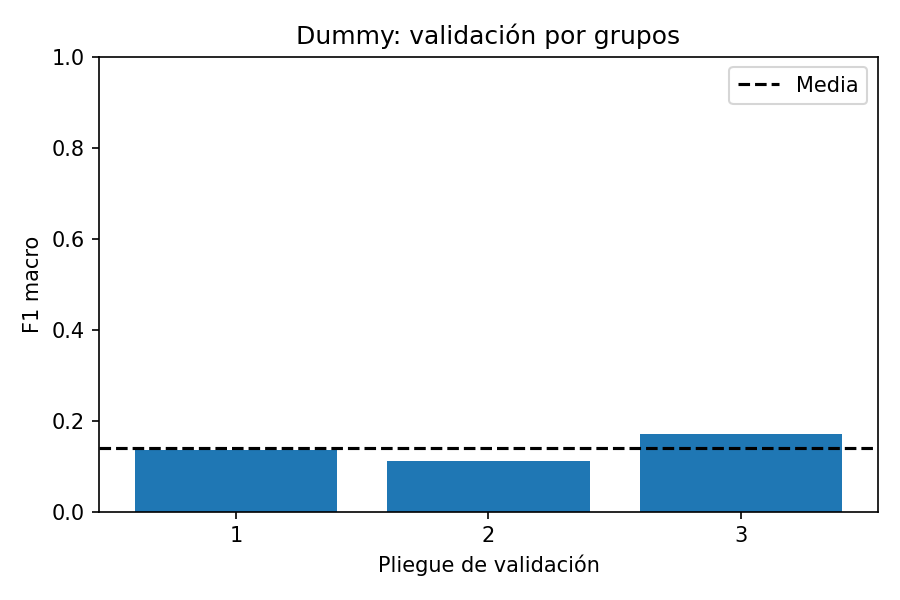

In [ ]:
resultado_base_cv = validar("Dummy", candidatos["Dummy"], familias["Dummy"])
display(Image(filename=str(RUN_DIR / "cv_Dummy.png")))

**Interpretación de la validación del modelo base.** El gráfico muestra el F1 macro de una regla que ignora las características EEG. La clase más frecuente se determina solo con el entrenamiento de cada pliegue y puede cambiar entre pliegues. Su desempeño es la referencia mínima para interpretar el aporte de los otros modelos; no demuestra capacidad de distinguir las tres condiciones.


In [ ]:
for nombre, pipeline in candidatos.items():
    if nombre != "Dummy":
        validar(nombre, pipeline, familias[nombre])
comparacion_cv = pd.DataFrame([resultados_cv[n] for n in candidatos])
comparacion_cv = comparacion_cv.sort_values(
    ["cv_f1_macro_mean", "candidato"], ascending=[False, True]).reset_index(drop=True)
comparacion_cv.to_csv(RUN_DIR / "comparacion_cv.csv", index=False)
display(comparacion_cv.drop(columns="run_id_cv"))

🏃 View run CV_LR_C0.1 at: http://127.0.0.1:5000/#/experiments/1/runs/b7d942f3333b422b9ba808ba9eff8a4a
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1


,candidato,tipo_modelo,cv_f1_macro_mean,cv_f1_macro_std,cv_f1_pliegue_1,cv_f1_pliegue_2,cv_f1_pliegue_3,avisos_convergencia,run_id_cv
0,LR_C0.1,regresion_logistica,0.743011,0.058526,0.808895,0.697039,0.723098,0,b7d942f3333b422b9ba808ba9eff8a4a


🏃 View run CV_LR_C1 at: http://127.0.0.1:5000/#/experiments/1/runs/4d0168ca424d45f1be90a487c34db3d0
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1


,candidato,tipo_modelo,cv_f1_macro_mean,cv_f1_macro_std,cv_f1_pliegue_1,cv_f1_pliegue_2,cv_f1_pliegue_3,avisos_convergencia,run_id_cv
0,LR_C1,regresion_logistica,0.745297,0.061934,0.815993,0.7006,0.719298,0,4d0168ca424d45f1be90a487c34db3d0


🏃 View run CV_LR_C10 at: http://127.0.0.1:5000/#/experiments/1/runs/8f10054e7183461fb0ed63b68fe3ba18
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1


,candidato,tipo_modelo,cv_f1_macro_mean,cv_f1_macro_std,cv_f1_pliegue_1,cv_f1_pliegue_2,cv_f1_pliegue_3,avisos_convergencia,run_id_cv
0,LR_C10,regresion_logistica,0.750304,0.054064,0.812077,0.727225,0.71161,0,8f10054e7183461fb0ed63b68fe3ba18


... (5 outputs left out)

,candidato,tipo_modelo,cv_f1_macro_mean,cv_f1_macro_std,cv_f1_pliegue_1,cv_f1_pliegue_2,cv_f1_pliegue_3,avisos_convergencia,run_id_cv
0,RF_d16_h2,random_forest,0.743683,0.070628,0.810053,0.669455,0.751542,0,b7567a7c7c3340a292d2660bf106eb2b


🏃 View run CV_RF_d16_h5 at: http://127.0.0.1:5000/#/experiments/1/runs/37a141ab53f2446eb8bd4779b4d135c6
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1


,candidato,tipo_modelo,cv_f1_macro_mean,cv_f1_macro_std,cv_f1_pliegue_1,cv_f1_pliegue_2,cv_f1_pliegue_3,avisos_convergencia,run_id_cv
0,RF_d16_h5,random_forest,0.74283,0.082583,0.821943,0.657167,0.749381,0,37a141ab53f2446eb8bd4779b4d135c6


,candidato,tipo_modelo,cv_f1_macro_mean,cv_f1_macro_std,cv_f1_pliegue_1,cv_f1_pliegue_2,cv_f1_pliegue_3,avisos_convergencia
0,LR_C10,regresion_logistica,0.750304,0.054064,0.812077,0.727225,0.711610,0
1,LR_C1,regresion_logistica,0.745297,0.061934,0.815993,0.700600,0.719298,0
2,RF_d16_h2,random_forest,0.743683,0.070628,0.810053,0.669455,0.751542,0
3,LR_C0.1,regresion_logistica,0.743011,0.058526,0.808895,0.697039,0.723098,0
4,RF_d16_h5,random_forest,0.742830,0.082583,0.821943,0.657167,0.749381,0
5,RF_d8_h5,random_forest,0.737854,0.078219,0.809461,0.654379,0.749721,0
6,RF_d8_h2,random_forest,0.726489,0.066769,0.783198,0.652900,0.743371,0
7,Dummy,base,0.140195,0.030147,0.136439,0.112102,0.172043,0


## 5. Evaluación y comparación

### Selección con datos de entrenamiento

Comparamos el F1 macro medio de los **mismos tres pliegues** para todos los candidatos. La desviación estándar describe la variación entre pliegues; no es un intervalo de confianza. Un empate exacto dentro de una familia se resuelve por el nombre del candidato para que la regla sea reproducible.

Elegimos la mejor LR y el mejor RF. Aplicamos el desempate del informe: una diferencia absoluta **menor que 0,01** favorece LR. La prueba sigue reservada y H2 no cambiará las variables finales.

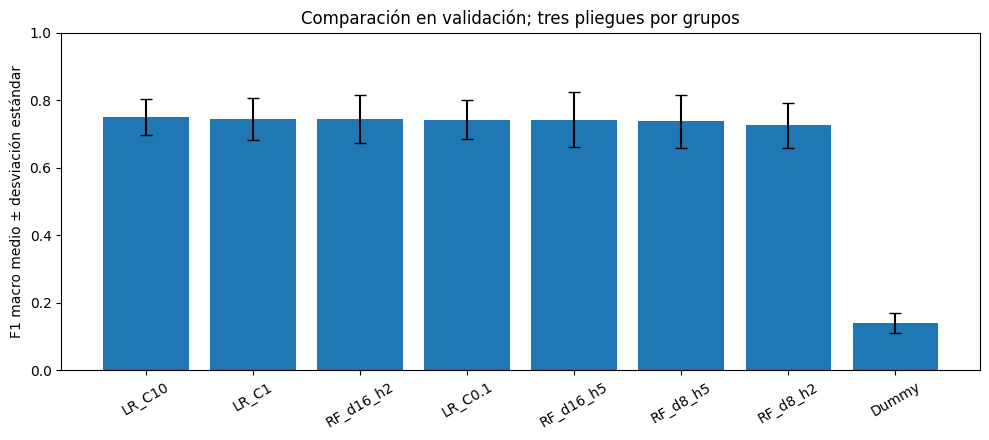

**Interpretación.** La mejor LR es **LR_C10** (0.750304) y el mejor RF es **RF_d16_h2** (0.743683). La diferencia RF−LR es **-0.006621**. Seleccionamos **LR_C10**. La diferencia absoluta entre familias es menor que 0,01; se prefiere LR. Esta decisión queda fijada antes de evaluar la prueba.

In [ ]:
mejor_lr = comparacion_cv.loc[comparacion_cv.tipo_modelo == "regresion_logistica"].iloc[0]
mejor_rf = comparacion_cv.loc[comparacion_cv.tipo_modelo == "random_forest"].iloc[0]
delta_h1 = float(mejor_rf.cv_f1_macro_mean - mejor_lr.cv_f1_macro_mean)
if abs(delta_h1) < 0.01:
    ganador = str(mejor_lr.candidato)
    motivo = "La diferencia absoluta entre familias es menor que 0,01; se prefiere LR."
elif delta_h1 > 0:
    ganador = str(mejor_rf.candidato)
    motivo = "RF obtiene mayor F1 macro medio en validación."
else:
    ganador = str(mejor_lr.candidato)
    motivo = "LR obtiene mayor F1 macro medio en validación."
seleccion = {"ganador": ganador, "motivo": motivo,
    "mejor_lr": str(mejor_lr.candidato), "mejor_rf": str(mejor_rf.candidato),
    "delta_h1": delta_h1, "margen_h1": 0.03, "h1_cumplida": bool(delta_h1 >= 0.03),
    "variables_finales": "512 actuales", "seleccion_antes_de_prueba": True}
guardar_json(seleccion, "seleccion.json")
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.bar(comparacion_cv.candidato, comparacion_cv.cv_f1_macro_mean,
    yerr=comparacion_cv.cv_f1_macro_std, capsize=4)
ax.set(ylabel="F1 macro medio ± desviación estándar", title="Comparación en validación; tres pliegues por grupos", ylim=(0, 1))
ax.tick_params(axis="x", rotation=30)
fig.tight_layout()
fig.savefig(RUN_DIR / "comparacion_validacion.png", dpi=150)
plt.show()
display(Markdown(f"**Interpretación.** La mejor LR es **{mejor_lr.candidato}** ({mejor_lr.cv_f1_macro_mean:.6f}) y el mejor RF es **{mejor_rf.candidato}** ({mejor_rf.cv_f1_macro_mean:.6f}). La diferencia RF−LR es **{delta_h1:+.6f}**. Seleccionamos **{ganador}**. {motivo} Esta decisión queda fijada antes de evaluar la prueba."))


### H2: aporte de la ventana anterior

Reutilizamos la **misma configuración del mejor RF con variables actuales**. Cambiamos únicamente el selector para incorporar los 476 predictores `lag1_`: ahora pasan 988 variables. Conservamos semilla y pliegues. No volvemos a buscar hiperparámetros y no añadimos este candidato a la selección final.

🏃 View run CV_RF_d16_h2_con_lag1 at: http://127.0.0.1:5000/#/experiments/1/runs/5c62e65849384d5c82ed3b5497d4d9f0
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1


,candidato,tipo_modelo,cv_f1_macro_mean,cv_f1_macro_std,cv_f1_pliegue_1,cv_f1_pliegue_2,cv_f1_pliegue_3,avisos_convergencia,run_id_cv
0,RF_d16_h2_con_lag1,random_forest,0.753805,0.076892,0.823703,0.671442,0.766269,0,5c62e65849384d5c82ed3b5497d4d9f0


,Predictores,F1 macro CV
0,512 actuales,0.743683
1,988 actuales + lag1_,0.753805


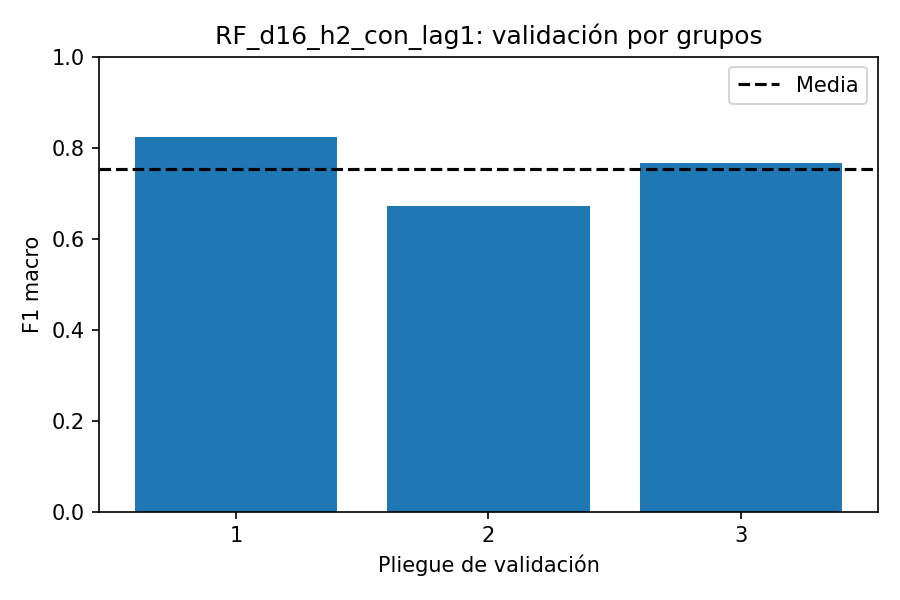

**Interpretación de H2 y su gráfico.** Con la configuración fija, agregar la ventana anterior cambia el F1 macro medio en **+0.010122**. El margen de 0,02 **no se alcanza**. Las tres barras muestran la variación entre los mismos grupos de validación. El análisis es secundario y no modifica el ganador **LR_C10** ni sus 512 variables actuales.

In [ ]:
nombre_h2 = str(mejor_rf.candidato) + "_con_lag1"
rf_h2 = construir_pipeline(clone(candidatos[str(mejor_rf.candidato)].named_steps["modelo"]), list(X.columns))
resultado_h2 = validar(nombre_h2, rf_h2, "random_forest", fase="hipotesis2")
delta_h2 = float(resultado_h2["cv_f1_macro_mean"] - mejor_rf.cv_f1_macro_mean)
hipotesis = {"delta_h1": delta_h1, "margen_h1": 0.03, "h1_cumplida": bool(delta_h1 >= 0.03),
    "delta_h2": delta_h2, "margen_h2": 0.02, "h2_cumplida": bool(delta_h2 >= 0.02)}
guardar_json(hipotesis, "hipotesis.json")
tabla_h2 = pd.DataFrame({"Predictores": ["512 actuales", "988 actuales + lag1_"],
    "F1 macro CV": [float(mejor_rf.cv_f1_macro_mean), resultado_h2["cv_f1_macro_mean"]]})
tabla_h2.to_csv(RUN_DIR / "comparacion_h2.csv", index=False)
display(tabla_h2)
display(Image(filename=str(RUN_DIR / f"cv_{nombre_h2}.png")))
display(Markdown(f"**Interpretación de H2 y su gráfico.** Con la configuración fija, agregar la ventana anterior cambia el F1 macro medio en **{delta_h2:+.6f}**. El margen de 0,02 **{'se alcanza' if delta_h2 >= 0.02 else 'no se alcanza'}**. Las tres barras muestran la variación entre los mismos grupos de validación. El análisis es secundario y no modifica el ganador **{ganador}** ni sus 512 variables actuales."))

### Evaluación final en prueba

La selección y el contraste de las dos hipótesis ya están cerrados. Reajustamos **Dummy, la mejor LR y el mejor RF** con las mismas 1.798 filas de entrenamiento. Los evaluamos sobre las mismas 566 filas reservadas, con las mismas métricas y 512 variables actuales. La diferencia respecto de evaluar solo ganador y base se explica en el registro de cambios.

Informamos accuracy, precisión macro, recall macro, F1 macro y métricas por clase con soporte. F1 macro da igual peso a las clases. El criterio de negocio se comprueba con **el recall de cada clase**, no con el recall macro.

Cada modelo tendrá matrices de confusión con conteos y proporciones por clase real, además de sus aciertos por grupo. Las predicciones se guardan para no repetir el ajuste si volvemos a ejecutar esta sección en el mismo lote. Mirar esta prueba no autoriza a cambiar el modelo, el umbral o las hipótesis.

In [ ]:
def metricas_clasificacion(real, pred):
    return {
        "accuracy": float(accuracy_score(real, pred)),
        "precision_macro": float(precision_score(real, pred, labels=CLASES, average="macro", zero_division=0)),
        "recall_macro": float(recall_score(real, pred, labels=CLASES, average="macro", zero_division=0)),
        "f1_macro": float(f1_score(real, pred, labels=CLASES, average="macro", zero_division=0)),
        **{f"recall_{c}": float(r) for c, r in zip(CLASES,
            recall_score(real, pred, labels=CLASES, average=None, zero_division=0))},
    }

def evaluar_prueba(nombre):
    pipeline = candidatos[nombre]
    carpeta = RUN_DIR / f"final_{nombre}"
    carpeta.mkdir(exist_ok=True)
    pred_file = carpeta / "predicciones.csv"
    if not pred_file.exists():
        modelo = clone(pipeline)
        with warnings.catch_warnings(record=True) as avisos:
            warnings.simplefilter("always")
            with threadpool_limits(limits=1):
                modelo.fit(X_train, y_train)
                pred = modelo.predict(X_test)
        joblib.dump(modelo, carpeta / "pipeline.joblib")
        (carpeta / "avisos.json").write_text(json.dumps({"avisos": [str(a.message) for a in avisos],
            "avisos_convergencia": sum(issubclass(a.category, ConvergenceWarning) for a in avisos)}, ensure_ascii=False), encoding="utf-8")
        pd.DataFrame({"fila_limpia": idx_test, "fila_csv": filas_csv[idx_test], "grupo": grupos_test,
            "real": y_test.to_numpy(), "pred": pred}).to_csv(pred_file, index=False)
    predicciones = pd.read_csv(pred_file)
    assert np.array_equal(predicciones.fila_limpia.to_numpy(), idx_test)
    assert np.array_equal(predicciones.real.to_numpy(), y_test.to_numpy())
    metricas = metricas_clasificacion(predicciones.real, predicciones.pred)
    cv = resultados_cv[nombre]
    metricas.update({"cv_f1_macro_mean": cv["cv_f1_macro_mean"], "cv_f1_macro_std": cv["cv_f1_macro_std"]})
    por_clase = pd.DataFrame(classification_report(predicciones.real, predicciones.pred,
        labels=CLASES, target_names=NOMBRES, output_dict=True, zero_division=0)).T
    por_clase.to_csv(carpeta / "metricas_clases.csv")
    predicciones["acierto"] = predicciones.real.eq(predicciones.pred)
    por_grupo = predicciones.groupby("grupo").agg(clase=("real", "first"),
        filas=("real", "size"), aciertos=("acierto", "sum"))
    por_grupo["proporcion_aciertos"] = por_grupo.aciertos / por_grupo.filas
    por_grupo.to_csv(carpeta / "aciertos_grupo.csv")
    cm = confusion_matrix(predicciones.real, predicciones.pred, labels=CLASES)
    cm_norm = confusion_matrix(predicciones.real, predicciones.pred, labels=CLASES, normalize="true")
    pd.DataFrame(cm, index=NOMBRES, columns=NOMBRES).to_csv(carpeta / "matriz_conteos.csv")
    pd.DataFrame(cm_norm, index=NOMBRES, columns=NOMBRES).to_csv(carpeta / "matriz_proporciones.csv")
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
    for ax, matriz, formato, titulo in zip(axes, [cm, cm_norm], ["d", ".2f"], ["Conteos", "Proporción por clase real"]):
        ConfusionMatrixDisplay(matriz, display_labels=NOMBRES).plot(ax=ax, colorbar=False, values_format=formato)
        ax.set_title(titulo)
        ax.tick_params(axis="x", rotation=15)
    fig.suptitle(f"{nombre}: prueba reservada")
    fig.tight_layout()
    fig.savefig(carpeta / "matriz_confusion.png", dpi=150)
    plt.show()
    evidencia = carpeta / "run_id.txt"
    if not evidencia.exists():
        with mlflow.start_run(run_name=f"FINAL_{nombre}") as run:
            registrar_contexto(nombre, familias[nombre], "prueba_final", pipeline)
            mlflow.set_tag("seleccionado_por_cv", str(nombre == ganador).lower())
            mlflow.log_params({"ganador_fijado_por_cv": ganador, "run_validacion": cv["run_id_cv"]})
            mlflow.log_metrics(metricas)
            for c, clase in zip(CLASES, NOMBRES):
                mlflow.log_metrics({f"{m}_clase_{c}": float(por_clase.loc[clase, m]) for m in ("precision", "recall", "f1-score", "support")})
            mlflow.log_artifacts(str(carpeta), artifact_path="evaluacion")
            mlflow.log_artifact(str(RUN_DIR / "seleccion.json"))
            mlflow.log_artifact(str(RUN_DIR / "hipotesis.json"))
            run_id = run.info.run_id
        evidencia.write_text(run_id, encoding="utf-8")
    display(por_clase)
    display(por_grupo.rename(columns={"clase": "codigo_clase"}))
    par = max((int(cm[i,j] + cm[j,i]), i, j) for i in range(3) for j in range(i+1, 3))
    n, i, j = par
    display(Markdown(f"**Interpretación de {nombre}.** La diagonal suma **{np.trace(cm)} de {len(predicciones)}** aciertos. La precisión, el recall y F1 por clase están en la tabla; los soportes de prueba son 116, 232 y 218. El par con más confusiones es **{NOMBRES[i]}–{NOMBRES[j]}**, con **{n}** errores sumando ambas direcciones. La matriz normalizada permite comparar clases con distintos soportes. La tabla por grupo muestra si el desempeño se concentra en algunos bloques; estos grupos no equivalen a participantes."))
    return {"candidato": nombre, "tipo_modelo": familias[nombre], **metricas,
        "run_id": evidencia.read_text(encoding="utf-8")}, predicciones

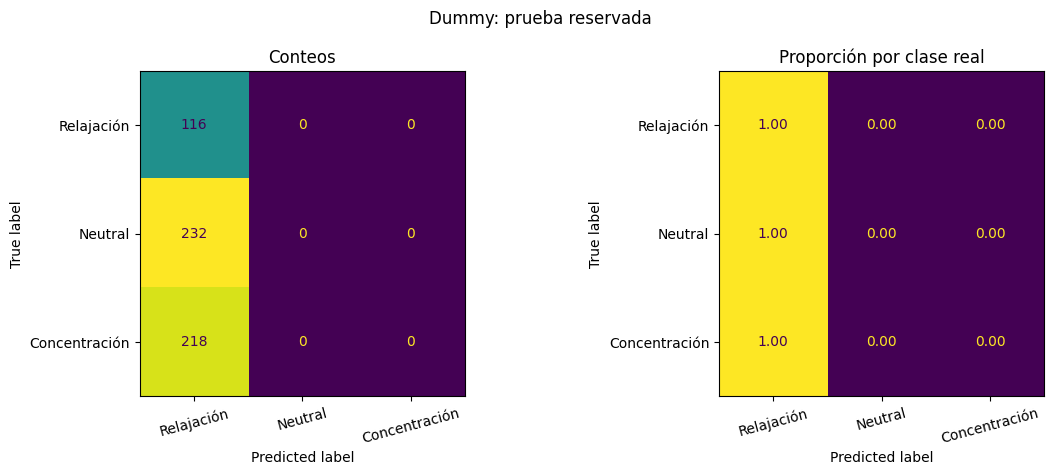

🏃 View run FINAL_Dummy at: http://127.0.0.1:5000/#/experiments/1/runs/8feee9bdec954ef98eff695ec27fc436
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1


,precision,recall,f1-score,support
Relajación,0.204947,1.000000,0.340176,116.000000
Neutral,0.000000,0.000000,0.000000,232.000000
Concentración,0.000000,0.000000,0.000000,218.000000
accuracy,0.204947,0.204947,0.204947,0.204947
macro avg,0.068316,0.333333,0.113392,566.000000
weighted avg,0.042003,0.204947,0.069718,566.000000


,codigo_clase,filas,aciertos,proporcion_aciertos
grupo,,,,
331,1,116,0,0.0
563,2,102,0,0.0
575,0,116,116,1.0
1456,2,116,0,0.0
2299,1,116,0,0.0


**Interpretación de Dummy.** La diagonal suma **116 de 566** aciertos. La precisión, el recall y F1 por clase están en la tabla; los soportes de prueba son 116, 232 y 218. El par con más confusiones es **Relajación–Neutral**, con **232** errores sumando ambas direcciones. La matriz normalizada permite comparar clases con distintos soportes. La tabla por grupo muestra si el desempeño se concentra en algunos bloques; estos grupos no equivalen a participantes.

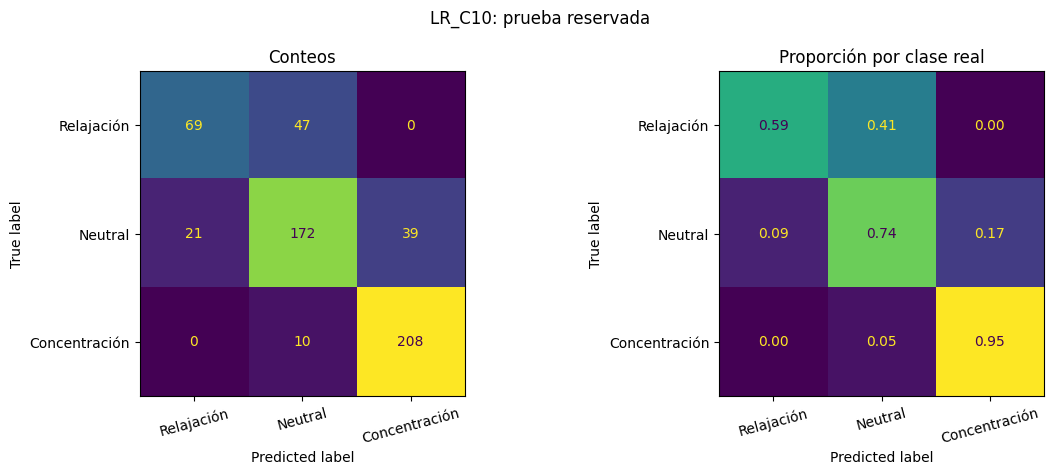

🏃 View run FINAL_LR_C10 at: http://127.0.0.1:5000/#/experiments/1/runs/e2d4bad8da734a3e8b6d4a299b7afeb6
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1


,precision,recall,f1-score,support
Relajación,0.766667,0.594828,0.669903,116.000000
Neutral,0.751092,0.741379,0.746204,232.000000
Concentración,0.842105,0.954128,0.894624,218.000000
accuracy,0.793286,0.793286,0.793286,0.793286
macro avg,0.786621,0.763445,0.770243,566.000000
weighted avg,0.789338,0.793286,0.787731,566.000000


,codigo_clase,filas,aciertos,proporcion_aciertos
grupo,,,,
331,1,116,73,0.629310
563,2,102,99,0.970588
575,0,116,69,0.594828
1456,2,116,109,0.939655
2299,1,116,99,0.853448


**Interpretación de LR_C10.** La diagonal suma **449 de 566** aciertos. La precisión, el recall y F1 por clase están en la tabla; los soportes de prueba son 116, 232 y 218. El par con más confusiones es **Relajación–Neutral**, con **68** errores sumando ambas direcciones. La matriz normalizada permite comparar clases con distintos soportes. La tabla por grupo muestra si el desempeño se concentra en algunos bloques; estos grupos no equivalen a participantes.

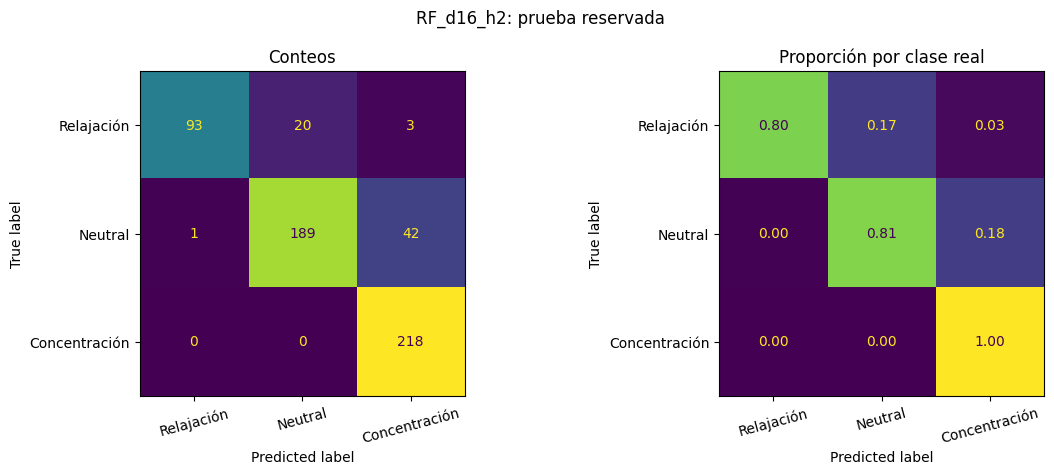

🏃 View run FINAL_RF_d16_h2 at: http://127.0.0.1:5000/#/experiments/1/runs/e6ca2e6daf8f49c9b83e26aa05d10eb8
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1


,precision,recall,f1-score,support
Relajación,0.989362,0.801724,0.885714,116.000000
Neutral,0.904306,0.814655,0.857143,232.000000
Concentración,0.828897,1.000000,0.906445,218.000000
accuracy,0.883392,0.883392,0.883392,0.883392
macro avg,0.907522,0.872126,0.883101,566.000000
weighted avg,0.892694,0.883392,0.881988,566.000000


,codigo_clase,filas,aciertos,proporcion_aciertos
grupo,,,,
331,1,116,84,0.724138
563,2,102,102,1.000000
575,0,116,93,0.801724
1456,2,116,116,1.000000
2299,1,116,105,0.905172


**Interpretación de RF_d16_h2.** La diagonal suma **500 de 566** aciertos. La precisión, el recall y F1 por clase están en la tabla; los soportes de prueba son 116, 232 y 218. El par con más confusiones es **Neutral–Concentración**, con **42** errores sumando ambas direcciones. La matriz normalizada permite comparar clases con distintos soportes. La tabla por grupo muestra si el desempeño se concentra en algunos bloques; estos grupos no equivalen a participantes.

PosixPath('/content/Proyecto_EEG_G01/20261119_011349_8f42c5/evaluacion_final_completa.json')

In [ ]:
nombres_finales = ["Dummy", str(mejor_lr.candidato), str(mejor_rf.candidato)]
filas_finales, predicciones_finales = [], {}
for nombre in nombres_finales:
    fila, predicciones = evaluar_prueba(nombre)
    filas_finales.append(fila)
    predicciones_finales[nombre] = predicciones
tabla_final = pd.DataFrame(filas_finales)
tabla_final["seleccionado_por_cv"] = tabla_final.candidato.eq(ganador)
tabla_final.to_csv(RUN_DIR / "comparacion_final.csv", index=False)
guardar_json({"ganador_previo": ganador, "modelos_evaluados": nombres_finales,
    "misma_prueba": True}, "evaluacion_final_completa.json")

,candidato,cv_f1_macro_mean,cv_f1_macro_std,accuracy,precision_macro,recall_macro,f1_macro,recall_0,recall_1,recall_2,seleccionado_por_cv
0,Dummy,0.140195,0.030147,0.204947,0.068316,0.333333,0.113392,1.000000,0.000000,0.000000,False
1,LR_C10,0.750304,0.054064,0.793286,0.786621,0.763445,0.770243,0.594828,0.741379,0.954128,True
2,RF_d16_h2,0.743683,0.070628,0.883392,0.907522,0.872126,0.883101,0.801724,0.814655,1.000000,False


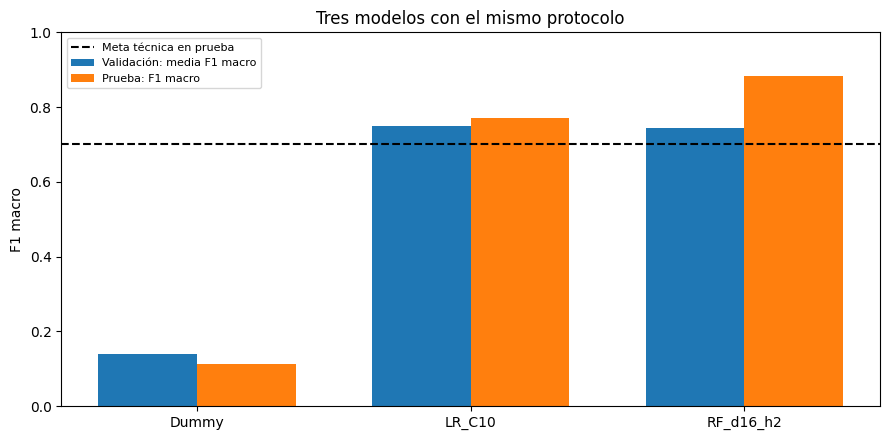

**Interpretación del gráfico comparativo.** La tabla contrasta la media de validación con una prueba reservada que tiene otros grupos y otra distribución de clases. Las diferencias entre ambas no se interpretan como un efecto aislado del modelo. El ganador sigue siendo **LR_C10**, seleccionado antes de abrir la prueba, con F1 macro de prueba **0.770243**, frente a **0.113392** de la referencia. La prueba de la otra familia se informa para cumplir la pauta y no se utiliza para volver a seleccionar.

In [ ]:
cols_tabla = ["candidato", "cv_f1_macro_mean", "cv_f1_macro_std", "accuracy",
    "precision_macro", "recall_macro", "f1_macro", "recall_0", "recall_1", "recall_2", "seleccionado_por_cv"]
display(tabla_final[cols_tabla].round(6))
fig, ax = plt.subplots(figsize=(9, 4.5))
pos = np.arange(len(tabla_final))
ax.bar(pos - 0.18, tabla_final.cv_f1_macro_mean, 0.36, label="Validación: media F1 macro")
ax.bar(pos + 0.18, tabla_final.f1_macro, 0.36, label="Prueba: F1 macro")
ax.axhline(0.70, color="black", linestyle="--", label="Meta técnica en prueba")
ax.set(xticks=pos, xticklabels=tabla_final.candidato, ylabel="F1 macro", ylim=(0, 1), title="Tres modelos con el mismo protocolo")
ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(RUN_DIR / "comparacion_final.png", dpi=150)
plt.show()
fila_ganador = tabla_final.set_index("candidato").loc[ganador]
fila_base = tabla_final.set_index("candidato").loc["Dummy"]
display(Markdown(f"**Interpretación del gráfico comparativo.** La tabla contrasta la media de validación con una prueba reservada que tiene otros grupos y otra distribución de clases. Las diferencias entre ambas no se interpretan como un efecto aislado del modelo. El ganador sigue siendo **{ganador}**, seleccionado antes de abrir la prueba, con F1 macro de prueba **{fila_ganador.f1_macro:.6f}**, frente a **{fila_base.f1_macro:.6f}** de la referencia. La prueba de la otra familia se informa para cumplir la pauta y no se utiliza para volver a seleccionar."))

## 6. Contraste de hipótesis y criterios de éxito

H1 y H2 son predicciones de trabajo con márgenes fijados antes de entrenar. Las contrastamos con el F1 macro medio de los pliegues de entrenamiento. Decir que una hipótesis no se cumple en este experimento no equivale a demostrar que nunca pueda ocurrir. No realizamos una prueba estadística de significancia ni estimamos incertidumbre a partir de filas como si fueran independientes.

El éxito técnico y la recomendación del segundo piloto se contrastan con el **ganador ya fijado**, en prueba. Comparamos los valores completos con los umbrales: un recall de 0,5948 no se convierte en un cumplimiento de 0,60 por redondeo.

In [ ]:
mejora_base = float(fila_ganador.f1_macro - fila_base.f1_macro)
min_recall = float(min(fila_ganador[f"recall_{c}"] for c in CLASES))
meta_tecnica = bool(fila_ganador.f1_macro >= 0.70)
recomendar_piloto = bool(meta_tecnica and min_recall >= 0.60)
contraste = pd.DataFrame([
    {"Criterio": "H1: RF − LR en validación", "Observado": delta_h1, "Umbral mínimo": 0.03, "Se cumple": delta_h1 >= 0.03},
    {"Criterio": "H2: RF con lag1_ − RF actual", "Observado": delta_h2, "Umbral mínimo": 0.02, "Se cumple": delta_h2 >= 0.02},
    {"Criterio": "Éxito técnico: F1 macro de prueba", "Observado": float(fila_ganador.f1_macro), "Umbral mínimo": 0.70, "Se cumple": meta_tecnica},
    {"Criterio": "Recall mínimo entre las tres clases", "Observado": min_recall, "Umbral mínimo": 0.60, "Se cumple": min_recall >= 0.60},
])
display(contraste)
contraste.to_csv(RUN_DIR / "contraste_informe.csv", index=False)
decision = "recomendar un segundo piloto con grabaciones independientes" if recomendar_piloto else "revisar primero el protocolo antes de recomendar otro piloto"
conclusion = {"ganador": ganador, "f1_macro": float(fila_ganador.f1_macro),
    "f1_base": float(fila_base.f1_macro), "mejora_base": mejora_base, "min_recall": min_recall,
    "meta_tecnica": meta_tecnica, "recomendar_piloto": recomendar_piloto, **hipotesis}
guardar_json(conclusion, "conclusiones.json")
display(Markdown(f"**H1:** {'se confirma según el margen definido' if delta_h1 >= 0.03 else 'se refuta en este experimento: no alcanza el margen definido'}; RF−LR = **{delta_h1:+.6f}**, frente a 0,03.\n\n**H2:** {'se confirma según el margen definido' if delta_h2 >= 0.02 else 'se refuta en este experimento: no alcanza el margen definido'}; cambio = **{delta_h2:+.6f}**, frente a 0,02.\n\n**Éxito técnico:** {'cumplido' if meta_tecnica else 'no cumplido'}. El ganador obtiene F1 macro = **{fila_ganador.f1_macro:.6f}** y supera a la referencia en **{mejora_base:.6f}**.\n\n**Decisión del informe:** corresponde **{decision}**. El recall mínimo por clase es **{min_recall:.6f}**; la regla exige además al menos 0,60 en cada condición."))

,Criterio,Observado,Umbral mínimo,Se cumple
0,H1: RF − LR en validación,-0.006621,0.03,False
1,H2: RF con lag1_ − RF actual,0.010122,0.02,False
2,Éxito técnico: F1 macro de prueba,0.770243,0.70,True
3,Recall mínimo entre las tres clases,0.594828,0.60,False


**H1:** se refuta en este experimento: no alcanza el margen definido; RF−LR = **-0.006621**, frente a 0,03.

**H2:** se refuta en este experimento: no alcanza el margen definido; cambio = **+0.010122**, frente a 0,02.

**Éxito técnico:** cumplido. El ganador obtiene F1 macro = **0.770243** y supera a la referencia en **0.656852**.

**Decisión del informe:** corresponde **revisar primero el protocolo antes de recomendar otro piloto**. El recall mínimo por clase es **0.594828**; la regla exige además al menos 0,60 en cada condición.

## 7. Conclusiones y limitaciones

### Resultados y selección del modelo

Las características EEG permitieron distinguir las tres condiciones experimentales con un desempeño superior al modelo base en esta partición. Se seleccionó la **regresión logística con regularización L2 y C = 10**, con F1 macro medio de validación de **0,750304**, frente a **0,743683** del mejor Random Forest. La diferencia absoluta fue **0,006621**; se aplicó la regla prevista en el informe, que favorece LR cuando la diferencia entre familias es menor que 0,01.

En prueba, LR acertó **449 de 566 ejemplos**, obtuvo una exactitud de **0,793286** y un F1 macro de **0,770243**. El modelo base acertó 116 ejemplos y obtuvo F1 macro de 0,113392. La mejora de LR frente a esa referencia fue **0,656852**.

Random Forest obtuvo el **mayor F1 macro observado en prueba: 0,883101**, con 500 aciertos y exactitud de 0,883392. También superó el recall de 0,60 en cada clase. Este resultado lo identifica como una alternativa para futuras validaciones independientes. La selección final se mantuvo en LR, elegida antes de abrir la prueba: utilizar ahora la prueba para cambiar el ganador incorporaría esos datos a la selección. Por tanto, distinguimos entre el modelo seleccionado por el protocolo y el modelo con mejor resultado en esta prueba concreta.

### Hipótesis y criterios de éxito

**H1 no se cumplió en este experimento:** la diferencia RF − LR fue −0,006621, por debajo del margen de +0,03. **H2 tampoco alcanzó el margen definido:** agregar `lag1_` al RF seleccionado aumentó el F1 macro medio de 0,743683 a 0,753805, una mejora de +0,010122, inferior a +0,02. Hubo una mejora observada al incorporar la ventana anterior, aunque no fue suficiente para confirmar H2. Estos contrastes usan los márgenes de trabajo del informe y no constituyen pruebas de significancia estadística.

El modelo seleccionado **cumplió la meta técnica de F1 macro ≥ 0,70**, pero el recall de relajación fue **0,594828 (59,48 %)**, por debajo del mínimo de 0,60. Los recalls de neutralidad y concentración fueron 0,741379 y 0,954128. Por eso **no se cumplió el criterio completo para recomendar otro piloto con el modelo seleccionado**. Conforme al informe, corresponde revisar primero el protocolo. Esta conclusión se aplica a LR y reconoce el mejor resultado observado de RF en la comparación adicional.

### Errores y utilidad para el problema planteado

La mayor confusión de LR se produjo entre **relajación y neutralidad**, con **68 errores**: 47 ejemplos de relajación se predijeron como neutrales y 21 neutrales se predijeron como relajación. Este patrón orienta la revisión de las instrucciones, los estímulos y las condiciones de captura que distinguen ambas condiciones. La matriz identifica la confusión, pero no permite demostrar cuál de esos factores la causó.

El costo para el problema planteado sería recomendar otra ronda de grabaciones apoyándose en una separación insuficiente entre condiciones. El aporte del notebook es mostrar esa dificultad antes de tomar la decisión y señalar qué condiciones conviene investigar.

El grupo de prueba **575**, correspondiente a relajación, presentó la menor proporción de aciertos de LR: **69 de 116 (59,48 %)**. En neutralidad, el grupo 331 obtuvo 73 de 116 aciertos (62,93 %) y el grupo 2299, 99 de 116 (85,34 %). En concentración, los grupos 563 y 1456 obtuvieron 99 de 102 (97,06 %) y 109 de 116 (93,97 %), respectivamente. Estas diferencias muestran por qué el promedio debe acompañarse del análisis por grupo.

### Limitaciones y siguiente paso

La ficha describe cuatro participantes y un dispositivo; el número de ventanas no aumenta la diversidad de personas. El CSV carece de identificadores de participante, sesión y tiempo. Los 24 grupos inferidos separan vínculos detectables entre ventanas, pero no garantizan que entrenamiento y prueba correspondan a personas diferentes.

La prueba contiene solo cinco grupos: uno de relajación y dos de cada otra clase. Por ello, el recall de relajación depende de un único grupo y la estimación tiene un alcance limitado. Las etiquetas representan condiciones inducidas por el experimento, y podrían influir factores como movimiento, parpadeos o características de las tareas. El análisis no determinó su efecto.

El paso posterior sería revisar las condiciones que más se confunden y disponer de grabaciones independientes, con identificadores seudónimos de participante y sesión, para evaluar modelos en personas ausentes del entrenamiento. Los resultados actuales apoyan esa planificación; no demuestran desempeño generalizable a participantes nuevos ni una aplicación clínica.

## 8. Registro de cambios respecto del informe

| Decisión | Informe | Implementación y motivo |
|---|---|---|
| Evaluación final | Ganador y modelo base | Se evaluaron base, mejor LR y mejor RF para cumplir la comparación de tres modelos de la Actividad 3.5. El ganador quedó fijado por validación antes de la prueba. |
| EDA | Diagnóstico inicial y decisiones de preparación | Se añadieron distribuciones, boxplots y correlaciones con interpretación escrita, usando entrenamiento para estudiar las relaciones. |
| Pipeline | Escalado de LR dentro del Pipeline | Se añadió un selector fijo de columnas. RF y Dummy también se implementaron en Pipeline, conservando la escala original. |
| Registro MLflow | Registrar datos, particiones, parámetros, métricas y matriz | Se utilizó `IEI097-G01`, con las etiquetas `grupo` y `tipo_modelo`, nueve runs de validación —incluido H2— y tres finales. |
| Instalación en Colab | Conservar la versión de scikit-learn y las particiones | Se usó Python 3.12, scikit-learn 1.5.2, NumPy 2.0.2, pandas 2.2.2 y SciPy 1.14.1. Se retiraron dos paquetes de clustering no utilizados para resolver conflictos de dependencias. |
| Empates exactos dentro de una familia | Sin regla específica | Se utilizó el orden por nombre del candidato como criterio determinista. Se conservó la preferencia por LR cuando la diferencia entre familias fue menor que 0,01. |
| Objetivo, hipótesis, semilla y umbrales | Fijados antes del modelado | Se conservaron el objetivo, la semilla 213410806, los grupos, los pliegues, H1 ≥ 0,03, H2 ≥ 0,02, F1 macro ≥ 0,70 y recall por clase ≥ 0,60. |

Los cambios de implementación no modificaron las hipótesis ni los umbrales después de conocer los resultados. H2 se mantuvo como análisis secundario y no alteró las 512 variables utilizadas en la evaluación final.

## Evidencias de MLflow

In [ ]:
URL_CAPTURAS = {
    "01_lista_runs.png": "https://github.com/asndjkasdnjkasdjnkasdj/-Lab01_EDA_Azocar_Benjamin/blob/main/evidencias_mlflow/01_lista_runs.png?raw=true",
    "02_compare.png": "https://github.com/asndjkasdnjkasdjnkasdj/-Lab01_EDA_Azocar_Benjamin/blob/main/evidencias_mlflow/02_compare.png?raw=true",
    "03_artefactos.png": "https://github.com/asndjkasdnjkasdjnkasdj/-Lab01_EDA_Azocar_Benjamin/blob/main/evidencias_mlflow/03_artefactos.png?raw=true",
}

Carpeta de capturas en Colab: /content/Proyecto_EEG_G01/20261119_011349_8f42c5/evidencias_mlflow


**01_lista_runs.png**

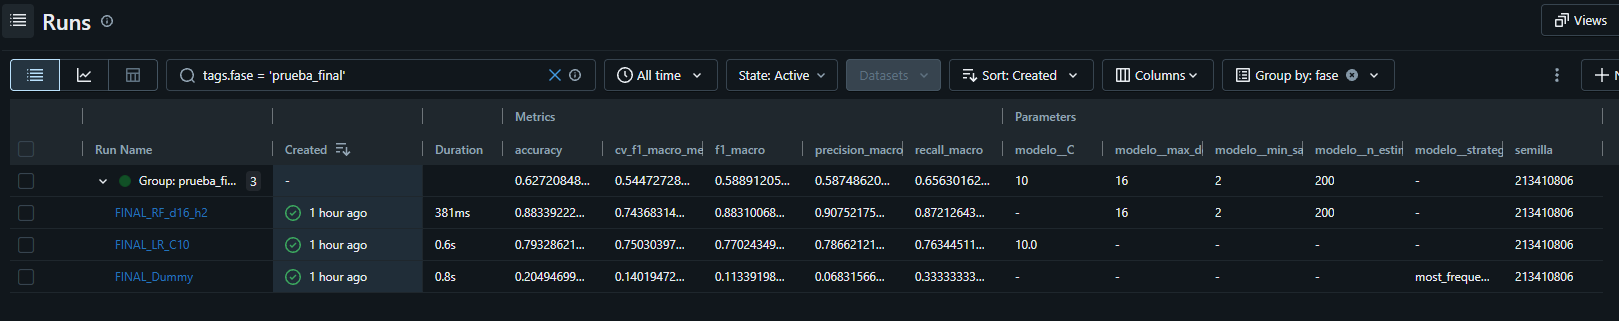

**02_compare.png**

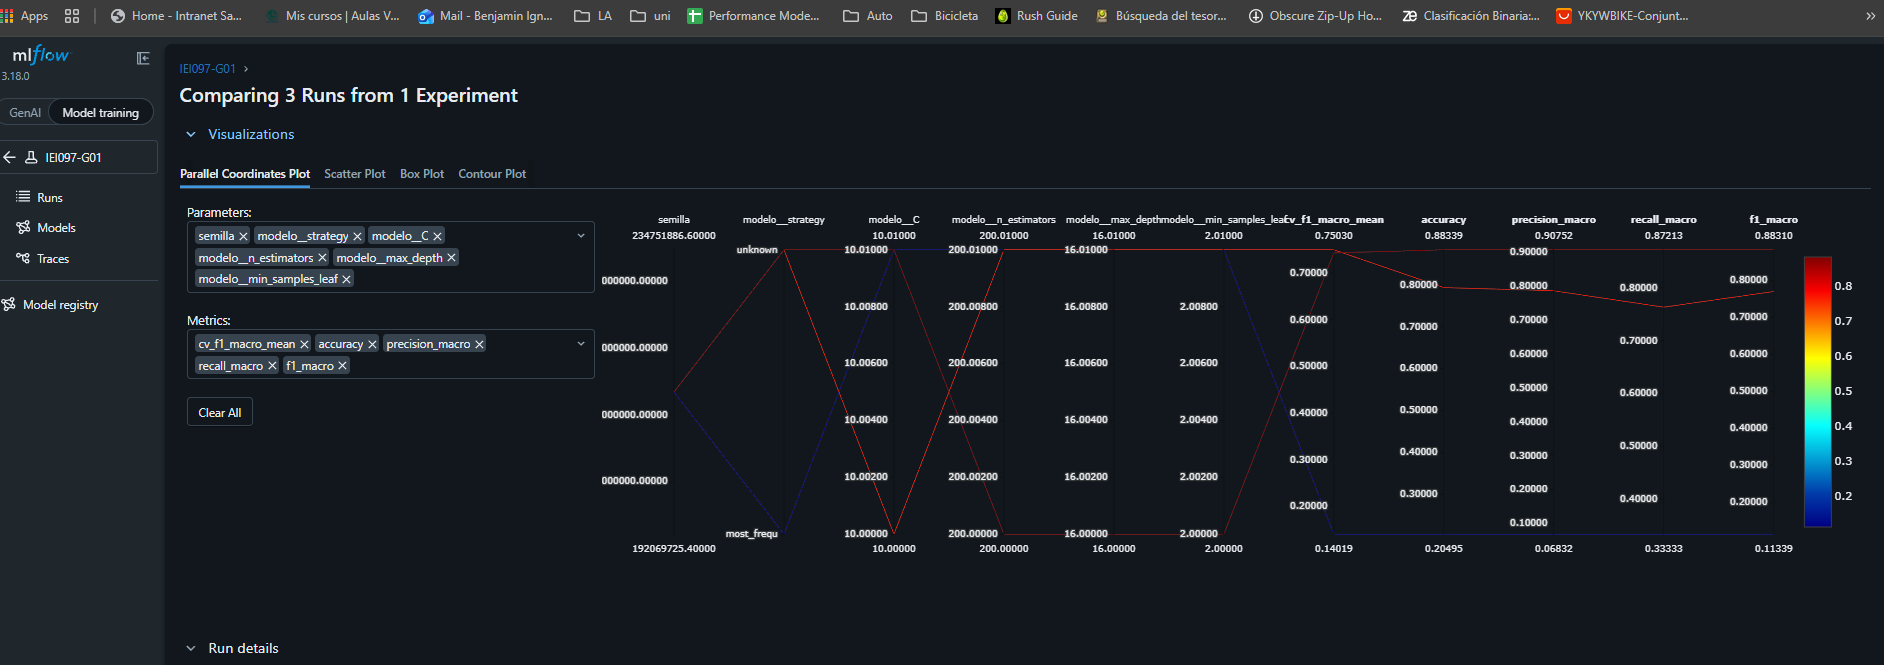

**03_artefactos.png**

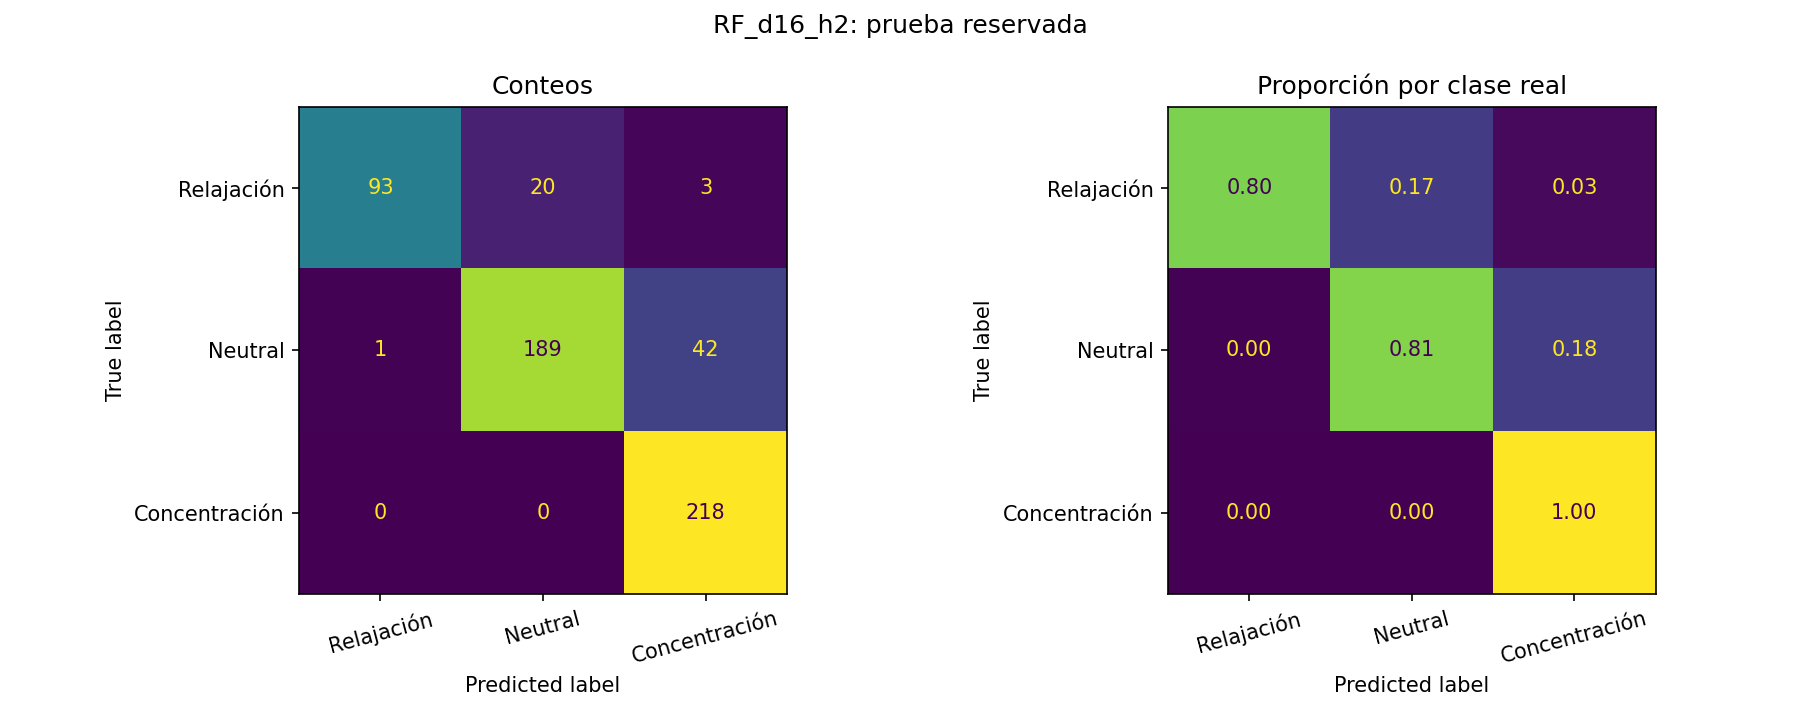

In [ ]:
print("Carpeta de capturas en Colab:", EVIDENCIAS)
capturas_insertadas = []
for nombre, url in URL_CAPTURAS.items():
    destino = EVIDENCIAS / nombre
    if url.strip():
        respuesta = requests.get(url, timeout=40)
        respuesta.raise_for_status()
        assert respuesta.headers.get("content-type", "").startswith("image/"), "Usa la URL Raw de la imagen."
        destino.write_bytes(respuesta.content)
    if destino.exists():
        display(Markdown(f"**{nombre}**"))
        display(Image(filename=str(destino), embed=True))
        capturas_insertadas.append(nombre)
    else:
        print("PENDIENTE:", nombre)

**Lectura de las evidencias.** La lista permite comprobar que los tres modelos tienen sus runs y métricas. Compare permite contrastar las configuraciones y sus resultados bajo el mismo protocolo. El detalle del ganador muestra que la matriz de confusión se conservó como artefacto del run. Antes de entregar verificamos que las imágenes realmente muestran nuestro experimento, los nombres de los modelos y valores coherentes con las tablas del notebook.

## Respaldo y comprobaciones de entrega

Exportamos los resultados y el listado de runs. El respaldo incluye la copia de los artefactos registrados y una copia consistente de la base SQLite. El ZIP es un respaldo; no sustituye el `.ipynb` con salidas ni las imágenes que pide la pauta.

In [ ]:
runs = mlflow.search_runs(experiment_ids=[EXPERIMENT_ID],
    filter_string=f"tags.lote = '{LOTE}' AND attributes.status = 'FINISHED'", output_format="pandas")
finales = runs.loc[runs["tags.fase"].eq("prueba_final")]
assert len(finales) == 3 and set(finales["tags.candidato"]) == set(nombres_finales)
assert set(finales["tags.grupo"]) == {GRUPO}
assert set(finales["tags.tipo_modelo"]) == {"base", "regresion_logistica", "random_forest"}
metricas_tabla = [c for c in cols_tabla if c not in ("candidato", "seleccionado_por_cv")]
for nombre in nombres_finales:
    fila_run = finales.loc[finales["tags.candidato"].eq(nombre)].iloc[0]
    fila_tabla = tabla_final.set_index("candidato").loc[nombre]
    for metrica in metricas_tabla:
        assert np.isclose(fila_run[f"metrics.{metrica}"], fila_tabla[metrica])
    assert fila_run["params.semilla"] == str(SEED)
runs.to_csv(RUN_DIR / "runs.csv", index=False)
cliente = mlflow.tracking.MlflowClient()
for run_id in runs.run_id:
    destino = RUN_DIR / "artefactos_mlflow" / run_id
    destino.mkdir(parents=True, exist_ok=True)
    mlflow.artifacts.download_artifacts(run_id=run_id, dst_path=str(destino))
with sqlite3.connect(str(ROOT / "mlflow.db")) as origen:
    with sqlite3.connect(str(RUN_DIR / "mlflow_respaldo.db")) as respaldo:
        origen.backup(respaldo)
display(finales[["tags.mlflow.runName", "tags.tipo_modelo", "metrics.f1_macro", "metrics.accuracy", "status"]])
print("Runs terminados de este lote:", len(runs), "| Runs finales:", len(finales))
print("Todas las métricas de la tabla final coinciden con MLflow.")

,tags.mlflow.runName,tags.tipo_modelo,metrics.f1_macro,metrics.accuracy,status
0,FINAL_RF_d16_h2,random_forest,0.883101,0.883392,FINISHED
1,FINAL_LR_C10,regresion_logistica,0.770243,0.793286,FINISHED
2,FINAL_Dummy,base,0.113392,0.204947,FINISHED


Runs terminados de este lote: 12 | Runs finales: 3
Todas las métricas de la tabla final coinciden con MLflow.


In [ ]:
checklist = pd.DataFrame([
    ["Carga desde la fuente y SHA-256", sha == EXPECTED_SHA],
    ["Partición del informe y grupos sin coincidencias", len(X_train) == 1798 and len(X_test) == 566 and set(grupos_train).isdisjoint(grupos_test)],
    ["Tres pliegues con las tres clases", all(set(y_train.iloc[val]) == set(CLASES) for _, val in pliegues)],
    ["Descriptivos, nulos, duplicados y cuatro figuras EDA", all((RUN_DIR / p).exists() for p in ["descriptivos_entrenamiento.csv", "diagnostico.json", "eda_clases.png", "eda_distribuciones.png", "eda_boxplots.png", "eda_correlaciones.png"])],
    ["Tres tipos de modelo en Pipeline", all(isinstance(candidatos[n], Pipeline) for n in nombres_finales)],
    ["Comparación de tres modelos y contraste H1/H2", len(tabla_final) == 3 and (RUN_DIR / "contraste_informe.csv").exists()],
    ["Tres runs finales con métricas comprobadas", len(finales) == 3],
    ["Tres capturas incorporadas", len(capturas_insertadas) == 3],
    ["Enlaces de informe y repositorio completados en configuración", URL_REPO.startswith("https://") and URL_INFORME.startswith("https://")],
], columns=["Revisión automática", "Cumple"])
display(checklist)
checklist.to_csv(RUN_DIR / "checklist.csv", index=False)
print("Revisión manual adicional: enlaces de portada, interpretaciones, registro de cambios, imágenes legibles y comprensión de ambas personas.")

,Revisión automática,Cumple
0,Carga desde la fuente y SHA-256,True
1,Partición del informe y grupos sin coincidencias,True
2,Tres pliegues con las tres clases,True
3,"Descriptivos, nulos, duplicados y cuatro figur...",True
4,Tres tipos de modelo en Pipeline,True
5,Comparación de tres modelos y contraste H1/H2,True
6,Tres runs finales con métricas comprobadas,True
7,Tres capturas incorporadas,True
8,Enlaces de informe y repositorio completados e...,False


Revisión manual adicional: enlaces de portada, interpretaciones, registro de cambios, imágenes legibles y comprensión de ambas personas.


## Entrega

Antes de entregar, completamos los enlaces de portada y configuración, el párrafo personal de conclusiones y las tres capturas. Revisamos que las imágenes coincidan con la ejecución que estamos documentando.

La pauta pide comprobar **Entorno de ejecución → Reiniciar sesión y ejecutar todo**. Lo hacemos cuando estén listas las celdas. Las credenciales permanecen en Secrets. La ejecución crea un nuevo lote; al terminar, actualizamos las capturas para que correspondan a sus runs y volvemos a ejecutar la celda que las inserta, las exportaciones y el checklist. Las capturas no se generan mediante Python.

El notebook de entrega debe conservar **las salidas visibles y ninguna celda con error**. Lo descargamos desde **Archivo → Descargar → Descargar .ipynb** después de guardar las evidencias.

En el repositorio dejamos como mínimo:

```text
IEI097_Proyecto_EEG_G01.ipynb
evidencias_mlflow/
    01_lista_runs.png
    02_compare.png
    03_artefactos.png
```

También conservamos `comparacion_cv.csv`, `comparacion_final.csv`, `comparacion_h2.csv`, `contraste_informe.csv`, `runs.csv` y `requirements.txt` en una carpeta `resultados/`. El informe PDF debe estar accesible mediante el enlace de portada. Omar participa como colaborador del repositorio. Benjamín sube a Moodle **el archivo `.ipynb` y el enlace del repositorio**; la pauta fija el lunes **30 de noviembre, a las 23:59**.

La descarga del respaldo puede ejecutarse de nuevo después de agregar las capturas. El servidor se mantiene abierto para poder consultar la interfaz; al terminar la sesión se perderá el servidor de Colab, por eso conservamos las salidas, capturas y respaldo.

In [ ]:
zip_entrega = shutil.make_archive(str(ROOT / (LOTE + "_entrega")), "zip", root_dir=ROOT, base_dir=LOTE)
print("Respaldo:", zip_entrega)
if IN_COLAB:
    from google.colab import files
    files.download(zip_entrega)
print("Descarga también el notebook desde Archivo → Descargar → Descargar .ipynb.")

Respaldo: /content/Proyecto_EEG_G01/20261119_011349_8f42c5_entrega.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Descarga también el notebook desde Archivo → Descargar → Descargar .ipynb.


## Referencias

Bird, J. J. (s. f.-a). *EEG feature generation* [Código fuente]. GitHub. https://github.com/jordan-bird/eeg-feature-generation

Bird, J. J. (s. f.-b). *EEG brainwave dataset: Mental state* (versión 2) [Conjunto de datos]. Kaggle. https://www.kaggle.com/datasets/birdy654/eeg-brainwave-dataset-mental-state

Bird, J. J., Manso, L. J., Ribeiro, E. P., Ekárt, A., & Faria, D. R. (2018). A study on mental state classification using EEG-based brain-machine interface. En *2018 International Conference on Intelligent Systems (IS)* (pp. 795–800). IEEE. https://doi.org/10.1109/IS.2018.8710576

Kaggle. (s. f.). *Kagglehub* [Documentación y código]. https://github.com/Kaggle/kagglehub

MLflow. (s. f.). *ML experiment tracking*. https://mlflow.org/docs/latest/ml/tracking/

scikit-learn developers. (s. f.). *cross_val_score* (versión 1.5.2) [Documentación técnica]. https://scikit-learn.org/1.5/modules/generated/sklearn.model_selection.cross_val_score.html

scikit-learn developers. (s. f.). *StratifiedGroupKFold* [Documentación técnica]. https://scikit-learn.org/1.5/modules/generated/sklearn.model_selection.StratifiedGroupKFold.html

Google. (s. f.). *Frequently asked questions: Past runtime versions*. https://research.google.com/colaboratory/runtime-version-faq.html

**Documentos del curso utilizados:** indicaciones de la Actividad 3.5 e informe CRISP-DM del Grupo 01, Actividad 2.13.